# Fondamenti di Machine Learning – Progetto finale
# Segmentazione della clientela con K-Means

### Azienda: FinTech Solutions S.p.A.

## Introduzione

L’obiettivo del progetto è segmentare la clientela di FinTech Solutions
S.p.A. attraverso l’algoritmo di clustering **K-Means**.

Il dataset contiene informazioni sui comportamenti di utilizzo della
carta di credito: saldo, acquisti, acquisti in un’unica soluzione e
rateali, anticipi di contante, frequenze di utilizzo, numero di
transazioni, limite di credito e pagamenti.

## Fasi del progetto

Il progetto si sviluppa attraverso le seguenti fasi:

- **Esplorazione e verifica della qualità dei dati:** analisi
  della struttura del dataset, dei valori mancanti, delle
  distribuzioni e delle possibili incoerenze tra variabili.

- **Preparazione dei dati:** trattamento delle anomalie,
  selezione delle feature, imputazione dei valori mancanti,
  trasformazione logaritmica delle variabili monetarie
  e standardizzazione.

- **Sviluppo della segmentazione:** confronto di diverse
  soluzioni K-Means attraverso inerzia, Silhouette Score,
  numerosità e interpretabilità dei gruppi.

- **Analisi dei segmenti:** descrizione dei cluster mediante
  medie e mediane, confronto con la clientela complessiva
  e visualizzazione attraverso heatmap e PCA.

- **Proposta di strategie di marketing:** formulazione di
  iniziative coerenti con i comportamenti osservati e
  definizione degli indicatori per verificarne l’efficacia.

- **Esportazione e valutazione conclusiva:** produzione dei
  dataset e delle tabelle di sintesi, verifica della coerenza
  dei risultati e discussione dei limiti e degli sviluppi futuri.

La segmentazione mira a individuare gruppi di clienti con comportamenti
simili, per formulare strategie commerciali e di comunicazione mirate.

Le anomalie saranno esaminate e trattate prima dell’imputazione dei
valori mancanti, documentando le regole adottate.

La scelta dei cluster sarà motivata considerando le metriche
di clustering, la numerosità dei gruppi e l’interpretabilità dei profili.

Le strategie di marketing rappresenteranno ipotesi basate sui
comportamenti osservati, da verificare attraverso campagne pilota.

## 1. Importazione delle librerie

Vengono importati gli strumenti necessari per manipolare i dati,
realizzare grafici, gestire i valori mancanti, trasformare e
standardizzare le variabili, applicare K-Means e valutare i risultati.

La PCA verrà utilizzata esclusivamente per visualizzare i cluster.

Viene inoltre definito un valore di riferimento per il parametro
random_state, utilizzato nelle operazioni che prevedono casualità
per favorire la riproducibilità dell’analisi.

In [ ]:
# Manipolazione e analisi dei dati
import pandas as pd
import numpy as np

# Visualizzazione
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Clustering e valutazione
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Riduzione dimensionale per la visualizzazione
from sklearn.decomposition import PCA

# Riproducibilità
RANDOM_STATE = 42

# Impostazioni grafiche e visualizzazione delle tabelle
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)

## 2. Caricamento del dataset

Il dataset viene caricato direttamente dall’URL pubblico indicato
nella consegna.

Il DataFrame df_original conserva i dati così come caricati dalla
fonte e non verrà modificato. Il DataFrame df costituisce una copia
di lavoro.

Vengono visualizzate le dimensioni del dataset e le prime cinque
righe in formato trasposto, per facilitare la lettura delle variabili.

In [ ]:
# Fonte indicata nella consegna
DATA_URL = (
    "https://proai-datasets.s3.eu-west-3.amazonaws.com/"
    "credit_card_customers.csv"
)

# Conservazione dei dati originali
df_original = pd.read_csv(DATA_URL)

# Copia di lavoro
df = df_original.copy(deep=True)

# Dimensioni
print(f"Numero di clienti (righe): {df.shape[0]}")
print(f"Numero di variabili (colonne): {df.shape[1]}")

# Anteprima trasposta
print("\nPrime cinque righe del dataset:")
display(df.head().T)

Numero di clienti (righe): 8950
Numero di variabili (colonne): 18

Prime cinque righe del dataset:


,0,1,2,3,4
CUST_ID,C10001,C10002,C10003,C10004,C10005
BALANCE,40.901,3202.467,2495.149,1666.671,817.714
BALANCE_FREQUENCY,0.818,0.909,1.000,0.636,1.000
PURCHASES,95.400,0.000,773.170,1499.000,16.000
ONEOFF_PURCHASES,0.000,0.000,773.170,1499.000,16.000
INSTALLMENTS_PURCHASES,95.400,0.000,0.000,0.000,0.000
CASH_ADVANCE,0.000,6442.945,0.000,205.788,0.000
PURCHASES_FREQUENCY,0.167,0.000,1.000,0.083,0.083
ONEOFF_PURCHASES_FREQUENCY,0.000,0.000,1.000,0.083,0.083
PURCHASES_INSTALLMENTS_FREQUENCY,0.083,0.000,0.000,0.000,0.000


## 3. Analisi preliminare del dataset

Il dataset caricato contiene 8.950 righe e 18 colonne, una delle quali
è l’identificativo CUST_ID.

L’anteprima mostra almeno un valore mancante in MINIMUM_PAYMENTS e
un caso in cui MINIMUM_PAYMENTS supera PAYMENTS. Queste osservazioni
richiedono controlli sull’intero dataset prima del preprocessing.

L’analisi preliminare comprende:

- verifica dei tipi di dato;
- conteggio e percentuale dei valori mancanti;
- controllo delle righe duplicate;
- controllo degli identificativi mancanti o duplicati;
- statistiche descrittive delle variabili numeriche.

In questa fase i dati vengono soltanto esaminati: non vengono
modificati valori, eliminate righe o effettuate imputazioni.

In [ ]:
# Riepilogo della struttura e dei valori mancanti
data_overview = pd.DataFrame({
    "tipo_dato": df.dtypes.astype(str),
    "valori_presenti": df.notna().sum(),
    "valori_mancanti": df.isna().sum(),
    "percentuale_mancanti": df.isna().mean().mul(100),
    "valori_distinti": df.nunique()
})

print("STRUTTURA DEL DATASET E VALORI MANCANTI")
display(data_overview)

# Controllo di righe e identificativi duplicati
print("\nCONTROLLO DUPLICATI E IDENTIFICATIVI")

print(
    "Righe completamente duplicate, oltre la prima occorrenza:",
    df.duplicated().sum()
)

print(
    "Identificativi CUST_ID mancanti:",
    df["CUST_ID"].isna().sum()
)

print(
    "Identificativi CUST_ID duplicati, oltre la prima occorrenza:",
    df["CUST_ID"].dropna().duplicated().sum()
)

# Statistiche descrittive delle variabili numeriche
print("\nSTATISTICHE DESCRITTIVE")

display(
    df.describe(
        percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]
    ).T
)

STRUTTURA DEL DATASET E VALORI MANCANTI


,tipo_dato,valori_presenti,valori_mancanti,percentuale_mancanti,valori_distinti
CUST_ID,object,8950,0,0.000,8950
BALANCE,float64,8950,0,0.000,8871
BALANCE_FREQUENCY,float64,8950,0,0.000,43
PURCHASES,float64,8950,0,0.000,6203
ONEOFF_PURCHASES,float64,8950,0,0.000,4014
INSTALLMENTS_PURCHASES,float64,8950,0,0.000,4452
CASH_ADVANCE,float64,8950,0,0.000,4323
PURCHASES_FREQUENCY,float64,8950,0,0.000,47
ONEOFF_PURCHASES_FREQUENCY,float64,8950,0,0.000,47
PURCHASES_INSTALLMENTS_FREQUENCY,float64,8950,0,0.000,47



CONTROLLO DUPLICATI E IDENTIFICATIVI
Righe completamente duplicate, oltre la prima occorrenza: 0
Identificativi CUST_ID mancanti: 0
Identificativi CUST_ID duplicati, oltre la prima occorrenza: 0

STATISTICHE DESCRITTIVE


,count,mean,std,min,25%,50%,75%,95%,99%,max
BALANCE,8950.000,1564.475,2081.532,0.000,128.282,873.385,2054.140,5909.112,9338.805,19043.139
BALANCE_FREQUENCY,8950.000,0.877,0.237,0.000,0.889,1.000,1.000,1.000,1.000,1.000
PURCHASES,8950.000,1003.205,2136.635,0.000,39.635,361.280,1110.130,3998.619,8977.290,49039.570
ONEOFF_PURCHASES,8950.000,592.437,1659.888,0.000,0.000,38.000,577.405,2671.094,6689.898,40761.250
INSTALLMENTS_PURCHASES,8950.000,411.068,904.338,0.000,0.000,89.000,468.637,1750.087,3886.241,22500.000
CASH_ADVANCE,8950.000,978.871,2097.164,0.000,0.000,0.000,1113.821,4647.169,9588.163,47137.212
PURCHASES_FREQUENCY,8950.000,0.490,0.401,0.000,0.083,0.500,0.917,1.000,1.000,1.000
ONEOFF_PURCHASES_FREQUENCY,8950.000,0.202,0.298,0.000,0.000,0.083,0.300,1.000,1.000,1.000
PURCHASES_INSTALLMENTS_FREQUENCY,8950.000,0.364,0.397,0.000,0.000,0.167,0.750,1.000,1.000,1.000
CASH_ADVANCE_FREQUENCY,8950.000,0.135,0.200,0.000,0.000,0.000,0.222,0.583,0.833,1.500


### Risultati dell’analisi preliminare

Il dataset contiene 8.950 clienti, identificati da codici CUST_ID
univoci e non mancanti. Non sono presenti righe completamente duplicate.

I valori mancanti riguardano:

- MINIMUM_PAYMENTS: 313 osservazioni, pari al 3,497%;
- CREDIT_LIMIT: una osservazione, pari a circa lo 0,011%.

Le statistiche descrittive suggeriscono distribuzioni asimmetriche
per diverse variabili monetarie. Ad esempio, PURCHASES presenta una
media di 1.003,205, una mediana di 361,280 e un massimo di 49.039,570.

I valori estremi non vengono considerati automaticamente errori:
potrebbero rappresentare comportamenti effettivi di clienti con
utilizzo particolarmente elevato della carta.

CASH_ADVANCE_FREQUENCY presenta un massimo di 1,5. I valori superiori
a 1 saranno esaminati separatamente, perché la loro interpretazione
dipende dalla definizione della frequenza utilizzata nella fonte.

TENURE assume valori interi compresi tra 6 e 12. Questi valori, da
soli, non permettono di verificare l’unità temporale indicata nella
consegna; si evita quindi di attribuire loro un’interpretazione
temporale non verificata.

### Controlli di coerenza prima dell’imputazione

Prima di trattare i valori mancanti vengono quantificate le seguenti
situazioni:

- valori numerici negativi o infiniti;
- frequenze e proporzioni al di fuori dell’intervallo previsto;
- conteggi di transazioni non interi;
- durata del rapporto non positiva o non intera;
- MINIMUM_PAYMENTS superiore a PAYMENTS;
- componenti degli acquisti superiori a PURCHASES;
- differenze tra PURCHASES e la somma delle due componenti.

Per i confronti monetari viene utilizzata una tolleranza di 0,01
unità monetarie, così da non segnalare differenze minime dovute
alla precisione numerica o all’arrotondamento.

I controlli tra variabili sono eseguiti soltanto sulle righe in cui
i valori necessari sono presenti.

Le segnalazioni rappresentano casi da approfondire, non una
classificazione automatica di tutte le osservazioni come errate.
In particolare, la relazione tra pagamento minimo e pagamento
effettuato richiede una regola di trattamento esplicita e motivata.

In questa fase nessun dato viene modificato.

In [ ]:
TOLLERANZA_IMPORTI = 0.01

# Variabili numeriche, senza modificare il dataset
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

# Frequenze/proporzioni per cui controlliamo l'intervallo [0, 1]
bounded_features = [
    "BALANCE_FREQUENCY",
    "PURCHASES_FREQUENCY",
    "ONEOFF_PURCHASES_FREQUENCY",
    "PURCHASES_INSTALLMENTS_FREQUENCY",
    "PRC_FULL_PAYMENT"
]

# Ogni controllo conserva una maschera delle righe segnalate
quality_flags = {}
quality_checks = []


def registra_controllo(nome, condizione, valutabili):
    valutabili = valutabili.fillna(False)
    segnalati = condizione.fillna(False) & valutabili

    quality_flags[nome] = segnalati

    n_valutabili = int(valutabili.sum())
    n_segnalati = int(segnalati.sum())

    quality_checks.append({
        "controllo": nome,
        "righe_valutabili": n_valutabili,
        "righe_segnalate": n_segnalati,
        "percentuale_su_valutabili": (
            100 * n_segnalati / n_valutabili
            if n_valutabili > 0 else np.nan
        )
    })


# 1. Valori negativi e infiniti
for col in numeric_columns:
    registra_controllo(
        f"{col}: valori negativi",
        df[col] < 0,
        df[col].notna()
    )

    registra_controllo(
        f"{col}: valori infiniti",
        np.isinf(df[col]),
        df[col].notna()
    )

# 2. Frequenze e proporzioni con intervallo previsto [0, 1]
for col in bounded_features:
    registra_controllo(
        f"{col}: fuori da [0, 1]",
        (df[col] < 0) | (df[col] > 1),
        df[col].notna()
    )

# CASH_ADVANCE_FREQUENCY viene esaminata separatamente
registra_controllo(
    "CASH_ADVANCE_FREQUENCY > 1: da verificare",
    df["CASH_ADVANCE_FREQUENCY"] > 1,
    df["CASH_ADVANCE_FREQUENCY"].notna()
)

# 3. Conteggi e durata
for col in ["CASH_ADVANCE_TRX", "PURCHASES_TRX", "TENURE"]:
    registra_controllo(
        f"{col}: valori non interi",
        df[col].mod(1).ne(0),
        df[col].notna()
    )

registra_controllo(
    "TENURE: valori non positivi",
    df["TENURE"] <= 0,
    df["TENURE"].notna()
)

# 4. Relazione tra pagamenti
payment_columns = ["MINIMUM_PAYMENTS", "PAYMENTS"]

registra_controllo(
    "MINIMUM_PAYMENTS > PAYMENTS",
    (
        df["MINIMUM_PAYMENTS"] - df["PAYMENTS"]
        > TOLLERANZA_IMPORTI
    ),
    df[payment_columns].notna().all(axis=1)
)

# 5. Relazioni tra acquisti e componenti
for col in ["ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES"]:
    registra_controllo(
        f"{col} > PURCHASES",
        df[col] - df["PURCHASES"] > TOLLERANZA_IMPORTI,
        df[[col, "PURCHASES"]].notna().all(axis=1)
    )

purchase_columns = [
    "PURCHASES",
    "ONEOFF_PURCHASES",
    "INSTALLMENTS_PURCHASES"
]

purchase_difference = (
    df["PURCHASES"]
    - df["ONEOFF_PURCHASES"]
    - df["INSTALLMENTS_PURCHASES"]
)

registra_controllo(
    "PURCHASES diverso dalla somma delle componenti",
    purchase_difference.abs() > TOLLERANZA_IMPORTI,
    df[purchase_columns].notna().all(axis=1)
)

# Riepilogo compatto: mostriamo soltanto i controlli con segnalazioni
quality_summary = pd.DataFrame(quality_checks).set_index("controllo")

print("CONTROLLI CON ALMENO UNA SEGNALAZIONE")
display(
    quality_summary.loc[quality_summary["righe_segnalate"] > 0]
)

print(
    "\nControlli senza segnalazioni:",
    int((quality_summary["righe_segnalate"] == 0).sum()),
    "su",
    len(quality_summary)
)

# Approfondimento dei pagamenti: casi con maggiore differenza
payment_cases = df.loc[
    quality_flags["MINIMUM_PAYMENTS > PAYMENTS"],
    ["CUST_ID", "MINIMUM_PAYMENTS", "PAYMENTS"]
].copy()

payment_cases["differenza"] = (
    payment_cases["MINIMUM_PAYMENTS"] - payment_cases["PAYMENTS"]
)

print("\nPAGAMENTI: 10 CASI CON DIFFERENZA MAGGIORE")
display(
    payment_cases.sort_values("differenza", ascending=False).head(10)
)

print(
    "Casi segnalati con PAYMENTS = 0:",
    int((payment_cases["PAYMENTS"] == 0).sum())
)

# Approfondimento degli acquisti
purchase_cases = df.loc[
    quality_flags["PURCHASES diverso dalla somma delle componenti"],
    ["CUST_ID"] + purchase_columns
].copy()

purchase_cases["differenza_totale_meno_componenti"] = (
    purchase_difference.loc[purchase_cases.index]
)

print("\nACQUISTI: 10 CASI CON SCOSTAMENTO ASSOLUTO MAGGIORE")
display(
    purchase_cases.loc[
        purchase_cases["differenza_totale_meno_componenti"]
        .abs()
        .sort_values(ascending=False)
        .head(10)
        .index
    ]
)

print("\nCASH_ADVANCE_FREQUENCY > 1: PRIME 10 OSSERVAZIONI")
display(
    df.loc[
        quality_flags["CASH_ADVANCE_FREQUENCY > 1: da verificare"],
        [
            "CUST_ID",
            "CASH_ADVANCE_FREQUENCY",
            "CASH_ADVANCE_TRX",
            "CASH_ADVANCE",
            "TENURE"
        ]
    ].head(10)
)

CONTROLLI CON ALMENO UNA SEGNALAZIONE


,righe_valutabili,righe_segnalate,percentuale_su_valutabili
controllo,,,
CASH_ADVANCE_FREQUENCY > 1: da verificare,8950,8,0.089
MINIMUM_PAYMENTS > PAYMENTS,8637,2365,27.382
ONEOFF_PURCHASES > PURCHASES,8950,3,0.034
INSTALLMENTS_PURCHASES > PURCHASES,8950,14,0.156
PURCHASES diverso dalla somma delle componenti,8950,19,0.212



Controlli senza segnalazioni: 43 su 48

PAGAMENTI: 10 CASI CON DIFFERENZA MAGGIORE


,CUST_ID,MINIMUM_PAYMENTS,PAYMENTS,differenza
4376,C14499,76406.208,2688.447,73717.761
7132,C17325,61031.619,302.484,60729.134
5657,C15815,56370.041,3746.306,52623.735
4462,C14586,50260.759,92.865,50167.894
5830,C15993,43132.728,3569.183,39563.545
567,C10591,38512.125,227.514,38284.610
5968,C16134,42629.551,4560.776,38068.775
1130,C11170,30528.432,568.781,29959.651
5298,C15448,31871.364,3332.361,28539.003
2774,C12853,28483.255,518.300,27964.954


Casi segnalati con PAYMENTS = 0: 0

ACQUISTI: 10 CASI CON SCOSTAMENTO ASSOLUTO MAGGIORE


,CUST_ID,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,differenza_totale_meno_componenti
6857,C17045,5629.410,0.000,6229.410,-600.000
5231,C15378,205.060,0.000,607.760,-402.700
5967,C16133,279.760,0.000,578.550,-298.790
6803,C16991,339.110,611.650,12.410,-284.950
8834,C19075,510.000,0.000,780.000,-270.000
6790,C16978,426.250,0.000,653.550,-227.300
5846,C16010,486.270,580.200,0.000,-93.930
510,C10533,400.410,0.000,489.390,-88.980
5737,C15897,0.000,0.000,66.950,-66.950
908,C10940,3393.250,3364.590,77.660,-49.000



CASH_ADVANCE_FREQUENCY > 1: PRIME 10 OSSERVAZIONI


,CUST_ID,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,CASH_ADVANCE,TENURE
681,C10708,1.250,12,7240.433,8
1626,C11680,1.167,24,3719.650,6
2555,C12629,1.125,12,1651.287,8
2608,C12684,1.100,20,4109.465,10
3038,C13127,1.500,18,1932.461,6
3253,C13347,1.167,10,2794.326,6
8055,C18273,1.091,28,6084.859,11
8365,C18588,1.143,26,2127.214,7


### Risultati dei controlli di coerenza

I controlli non hanno rilevato valori numerici negativi o infiniti,
conteggi di transazioni non interi o valori di TENURE non positivi
o non interi.

Sono state individuate le seguenti situazioni da approfondire:

- 2.365 righe con MINIMUM_PAYMENTS superiore a PAYMENTS,
  pari al 27,382% delle 8.637 righe confrontabili;
- 19 righe con una differenza superiore alla tolleranza di 0,01
  tra PURCHASES e la somma delle componenti;
- 8 righe con CASH_ADVANCE_FREQUENCY superiore a 1.

Le altre frequenze e proporzioni controllate rispettano
l’intervallo [0, 1].

Le segnalazioni sui pagamenti sono particolarmente numerose:
considerarle tutte valori non validi porterebbe la quota da
imputare in MINIMUM_PAYMENTS a circa il 29,92%, includendo i
valori già mancanti.

Prima di adottare una regola di trattamento, vengono quindi
esaminate l’entità degli scostamenti e la sovrapposizione tra
le segnalazioni.

I controlli descrivono relazioni osservate nei dati. Non permettono
da soli di stabilire quale valore sia errato o di ricostruirne
il valore corretto.

In [ ]:
# 1. Entità degli scostamenti sui pagamenti
payment_diagnostics = df.loc[
    quality_flags["MINIMUM_PAYMENTS > PAYMENTS"],
    ["CUST_ID", "MINIMUM_PAYMENTS", "PAYMENTS"]
].copy()

payment_diagnostics["differenza"] = (
    payment_diagnostics["MINIMUM_PAYMENTS"]
    - payment_diagnostics["PAYMENTS"]
)

# La sostituzione dello zero evita divisioni per zero
payment_diagnostics["rapporto_minimo_pagato"] = (
    payment_diagnostics["MINIMUM_PAYMENTS"]
    / payment_diagnostics["PAYMENTS"].replace(0, np.nan)
)

print("ENTITÀ DEGLI SCOSTAMENTI NEI PAGAMENTI")
display(
    payment_diagnostics[
        ["differenza", "rapporto_minimo_pagato"]
    ].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).T
)

# Impatto ipotetico dell'invalidazione: nessuna modifica ai dati
minimum_to_impute = (
    df["MINIMUM_PAYMENTS"].isna()
    | quality_flags["MINIMUM_PAYMENTS > PAYMENTS"]
)

print(
    "\nMINIMUM_PAYMENTS da imputare se invalidassimo "
    "tutti i casi segnalati:",
    int(minimum_to_impute.sum())
)

print(
    "Percentuale sull'intero dataset:",
    f"{minimum_to_impute.mean() * 100:.2f}%"
)

# 2. Elenco completo delle differenze sugli acquisti
purchase_diagnostics = df.loc[
    quality_flags["PURCHASES diverso dalla somma delle componenti"],
    [
        "CUST_ID",
        "PURCHASES",
        "ONEOFF_PURCHASES",
        "INSTALLMENTS_PURCHASES"
    ]
].copy()

purchase_diagnostics["somma_componenti"] = (
    purchase_diagnostics["ONEOFF_PURCHASES"]
    + purchase_diagnostics["INSTALLMENTS_PURCHASES"]
)

purchase_diagnostics["differenza"] = (
    purchase_diagnostics["PURCHASES"]
    - purchase_diagnostics["somma_componenti"]
)

print("\nTUTTI I CASI SEGNALATI SUGLI ACQUISTI")
display(
    purchase_diagnostics.sort_values(
        by="differenza",
        key=lambda values: values.abs(),
        ascending=False
    )
)

# 3. Sovrapposizione tra le tre principali segnalazioni
main_flags = pd.DataFrame({
    "pagamento_minimo_superiore": quality_flags[
        "MINIMUM_PAYMENTS > PAYMENTS"
    ],
    "acquisti_non_coincidenti": quality_flags[
        "PURCHASES diverso dalla somma delle componenti"
    ],
    "frequenza_anticipi_superiore_a_1": quality_flags[
        "CASH_ADVANCE_FREQUENCY > 1: da verificare"
    ]
})

flag_combinations = (
    main_flags
    .groupby(main_flags.columns.tolist())
    .size()
    .rename("numero_clienti")
    .reset_index()
)

print("\nCOMBINAZIONI DELLE SEGNALAZIONI")
display(flag_combinations)

print(
    "\nClienti con almeno una delle tre segnalazioni:",
    int(main_flags.any(axis=1).sum())
)

ENTITÀ DEGLI SCOSTAMENTI NEI PAGAMENTI


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
differenza,2365.000,1076.638,3954.447,0.071,67.998,196.081,564.866,1630.141,4015.618,18066.095,73717.761
rapporto_minimo_pagato,2365.000,5.241,35.727,1.000,1.159,1.416,1.923,3.103,9.102,77.399,1369.070



MINIMUM_PAYMENTS da imputare se invalidassimo tutti i casi segnalati: 2678
Percentuale sull'intero dataset: 29.92%

TUTTI I CASI SEGNALATI SUGLI ACQUISTI


,CUST_ID,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,somma_componenti,differenza
6857,C17045,5629.410,0.000,6229.410,6229.410,-600.000
5231,C15378,205.060,0.000,607.760,607.760,-402.700
5967,C16133,279.760,0.000,578.550,578.550,-298.790
6803,C16991,339.110,611.650,12.410,624.060,-284.950
8834,C19075,510.000,0.000,780.000,780.000,-270.000
6790,C16978,426.250,0.000,653.550,653.550,-227.300
5846,C16010,486.270,580.200,0.000,580.200,-93.930
510,C10533,400.410,0.000,489.390,489.390,-88.980
5737,C15897,0.000,0.000,66.950,66.950,-66.950
908,C10940,3393.250,3364.590,77.660,3442.250,-49.000



COMBINAZIONI DELLE SEGNALAZIONI


,pagamento_minimo_superiore,acquisti_non_coincidenti,frequenza_anticipi_superiore_a_1,numero_clienti
0,False,False,False,6569
1,False,False,True,4
2,False,True,False,12
3,True,False,False,2354
4,True,False,True,4
5,True,True,False,7



Clienti con almeno una delle tre segnalazioni: 2381


### Scelte di trattamento delle anomalie

I controlli evidenziano problemi di diversa natura, che vengono
trattati con regole distinte.

#### MINIMUM_PAYMENTS

In 2.365 osservazioni MINIMUM_PAYMENTS supera PAYMENTS. La differenza
mediana nei casi segnalati è di 196,081 unità monetarie.

Invalidare tutti questi valori porterebbe a imputare 2.678
osservazioni, pari al 29,92% della colonna, includendo i valori
originariamente mancanti.

La documentazione disponibile non permette di stabilire con certezza
la comparabilità delle due grandezze né di ricostruire i valori corretti.

Si esclude quindi MINIMUM_PAYMENTS dalle variabili utilizzate nel
clustering, conservandola nei dati originali. Questa scelta evita
sia l’eliminazione di una quota consistente di clienti sia
un’imputazione estesa su una variabile di interpretazione incerta.

L’analisi dei pagamenti continuerà a utilizzare PAYMENTS e
PRC_FULL_PAYMENT. La rinuncia a MINIMUM_PAYMENTS costituisce
un limite informativo del modello.

#### Coerenza degli acquisti

In 19 righe la somma di ONEOFF_PURCHASES e INSTALLMENTS_PURCHASES
supera PURCHASES oltre la tolleranza prevista.

Assumendo che le componenti e il totale siano riferiti allo stesso
periodo e alla stessa base di calcolo, queste righe vengono escluse
dal dataset di modellazione e conservate separatamente.

Non viene modificato automaticamente il totale, perché non è
possibile identificare quale importo sia errato.

#### CASH_ADVANCE_FREQUENCY

Per il progetto si adotta l’ipotesi operativa che
CASH_ADVANCE_FREQUENCY rappresenti una frequenza compresa tra 0 e 1.

Gli 8 valori superiori a 1 vengono pertanto sostituiti con valori
mancanti, che saranno imputati nella fase successiva.

Questa regola dipende dall’interpretazione adottata: se la variabile
rappresentasse invece un tasso non limitato superiormente a 1,
il trattamento dovrebbe essere rivisto.

#### Tracciabilità

I dati originali restano invariati. Vengono conservati separatamente
i clienti esclusi e gli indicatori delle anomalie.

Da questo punto le analisi e il modello utilizzeranno df_clean,
così che il trattamento effettuato sia effettivamente recepito
dai passaggi successivi.

In [ ]:
# Registro delle segnalazioni sui dati originali
quality_audit = df[["CUST_ID"]].copy()
quality_audit = quality_audit.join(main_flags)

# 1. Separazione delle righe con acquisti non coerenti
exclude_purchase_rows = quality_flags[
    "PURCHASES diverso dalla somma delle componenti"
]

df_excluded = df.loc[exclude_purchase_rows].copy()
df_excluded["motivo_esclusione"] = (
    "PURCHASES non coerente con la somma delle componenti"
)

# Dataset destinato ai passaggi successivi
df_clean = df.loc[~exclude_purchase_rows].copy()

# 2. Esclusione della variabile ambigua dal dataset di lavoro
# La colonna rimane disponibile in df_original e df
excluded_features = ["MINIMUM_PAYMENTS"]
df_clean = df_clean.drop(columns=excluded_features)

# 3. Invalidazione delle frequenze secondo l'ipotesi dichiarata
invalid_cash_frequency = (
    (df_clean["CASH_ADVANCE_FREQUENCY"] < 0)
    | (df_clean["CASH_ADVANCE_FREQUENCY"] > 1)
)

n_invalid_cash_frequency = int(invalid_cash_frequency.sum())

df_clean.loc[
    invalid_cash_frequency, "CASH_ADVANCE_FREQUENCY"
] = np.nan

# Aggiornamento del registro
quality_audit["escluso_dal_modello"] = exclude_purchase_rows
quality_audit["frequenza_anticipi_invalidata"] = (
    quality_audit.index.isin(
        df_clean.index[invalid_cash_frequency]
    )
)

# Verifiche della coerenza del trattamento
assert len(df_clean) + len(df_excluded) == len(df_original)
assert df_clean.index.intersection(df_excluded.index).empty
assert "MINIMUM_PAYMENTS" not in df_clean.columns

remaining_purchase_difference = (
    df_clean["PURCHASES"]
    - df_clean["ONEOFF_PURCHASES"]
    - df_clean["INSTALLMENTS_PURCHASES"]
)

assert (
    remaining_purchase_difference.abs() <= TOLLERANZA_IMPORTI
).all()

assert (
    df_clean["CASH_ADVANCE_FREQUENCY"]
    .dropna()
    .between(0, 1)
    .all()
)

# Riepilogo del trattamento
treatment_summary = pd.DataFrame({
    "indicatore": [
        "Clienti originali",
        "Clienti esclusi per incoerenza negli acquisti",
        "Clienti mantenuti per il modello",
        "Percentuale di clienti mantenuti",
        "Frequenze anticipi convertite in mancanti"
    ],
    "valore": [
        len(df_original),
        len(df_excluded),
        len(df_clean),
        100 * len(df_clean) / len(df_original),
        n_invalid_cash_frequency
    ]
})

print("RIEPILOGO DEL TRATTAMENTO")
display(treatment_summary)

print("\nFeature esclusa:", excluded_features)
print("Dimensioni di df_clean:", df_clean.shape)

# Valori mancanti effettivi prima dell'imputazione
missing_after_treatment = pd.DataFrame({
    "valori_mancanti": df_clean.isna().sum(),
    "percentuale": df_clean.isna().mean().mul(100)
})

print("\nVALORI MANCANTI DOPO IL TRATTAMENTO, PRIMA DELL'IMPUTAZIONE")
display(
    missing_after_treatment.loc[
        missing_after_treatment["valori_mancanti"] > 0
    ]
)

print("\nControlli sul trattamento superati.")

RIEPILOGO DEL TRATTAMENTO


,indicatore,valore
0,Clienti originali,8950.000
1,Clienti esclusi per incoerenza negli acquisti,19.000
2,Clienti mantenuti per il modello,8931.000
3,Percentuale di clienti mantenuti,99.788
4,Frequenze anticipi convertite in mancanti,8.000



Feature esclusa: ['MINIMUM_PAYMENTS']
Dimensioni di df_clean: (8931, 17)

VALORI MANCANTI DOPO IL TRATTAMENTO, PRIMA DELL'IMPUTAZIONE


,valori_mancanti,percentuale
CASH_ADVANCE_FREQUENCY,8,0.090
CREDIT_LIMIT,1,0.011



Controlli sul trattamento superati.


### Esito del trattamento

Il dataset di lavoro df_clean contiene 8.931 clienti, pari al
99,788% delle osservazioni originali, e 16 variabili numeriche
oltre all’identificativo CUST_ID.

Sono state separate 19 righe con incoerenze negli acquisti,
conservate in df_excluded. MINIMUM_PAYMENTS è stata esclusa
dalle feature per le motivazioni documentate.

Prima dell’imputazione risultano mancanti:

- 8 valori di CASH_ADVANCE_FREQUENCY, introdotti dal trattamento;
- un valore di CREDIT_LIMIT, già assente nella fonte.

I controlli hanno verificato che il dataset risultante rispetti
le regole operative adottate. Questi controlli non costituiscono
una verifica indipendente delle ipotesi sulle definizioni delle
variabili.

## 4. Analisi esplorativa dei dati

### Distribuzione delle variabili monetarie

L’analisi viene effettuata su df_clean, prima dell’imputazione
e delle trasformazioni.

Per ciascuna variabile monetaria vengono esaminati:

- media e mediana;
- 95° e 99° percentile;
- valore massimo;
- percentuale di valori pari a zero;
- indice di asimmetria.

Un’asimmetria positiva indica una distribuzione con una coda
verso i valori elevati. Una distanza marcata tra media e mediana
può fornire un ulteriore segnale di questa caratteristica.

Gli istogrammi mostrano la forma delle distribuzioni nella scala
originale. La presenza di valori estremi non implica automaticamente
un errore e non comporta, da sola, l’eliminazione delle osservazioni.

Questa analisi servirà a motivare l’eventuale applicazione di log1p,
che comprime le differenze tra importi elevati e consente di
mantenere i valori pari a zero.

DISTRIBUZIONE DELLE VARIABILI MONETARIE


,valori_presenti,media,mediana,percentile_95,percentile_99,massimo,percentuale_zeri,asimmetria
BALANCE,8931,1564.847,873.090,5908.846,9331.187,19043.139,0.896,2.392
PURCHASES,8931,1003.700,361.070,3998.475,8989.070,49039.570,22.864,8.144
ONEOFF_PURCHASES,8931,593.173,39.000,2670.660,6694.234,40761.250,48.013,10.041
INSTALLMENTS_PURCHASES,8931,410.527,88.870,1749.755,3879.672,22500.000,43.825,7.317
CASH_ADVANCE,8931,980.114,0.000,4659.625,9591.325,47137.212,51.674,5.164
PAYMENTS,8931,1731.028,857.534,6081.942,13554.719,50721.483,2.687,5.903
CREDIT_LIMIT,8930,4494.550,3000.000,12000.000,17000.000,30000.000,0.000,1.523


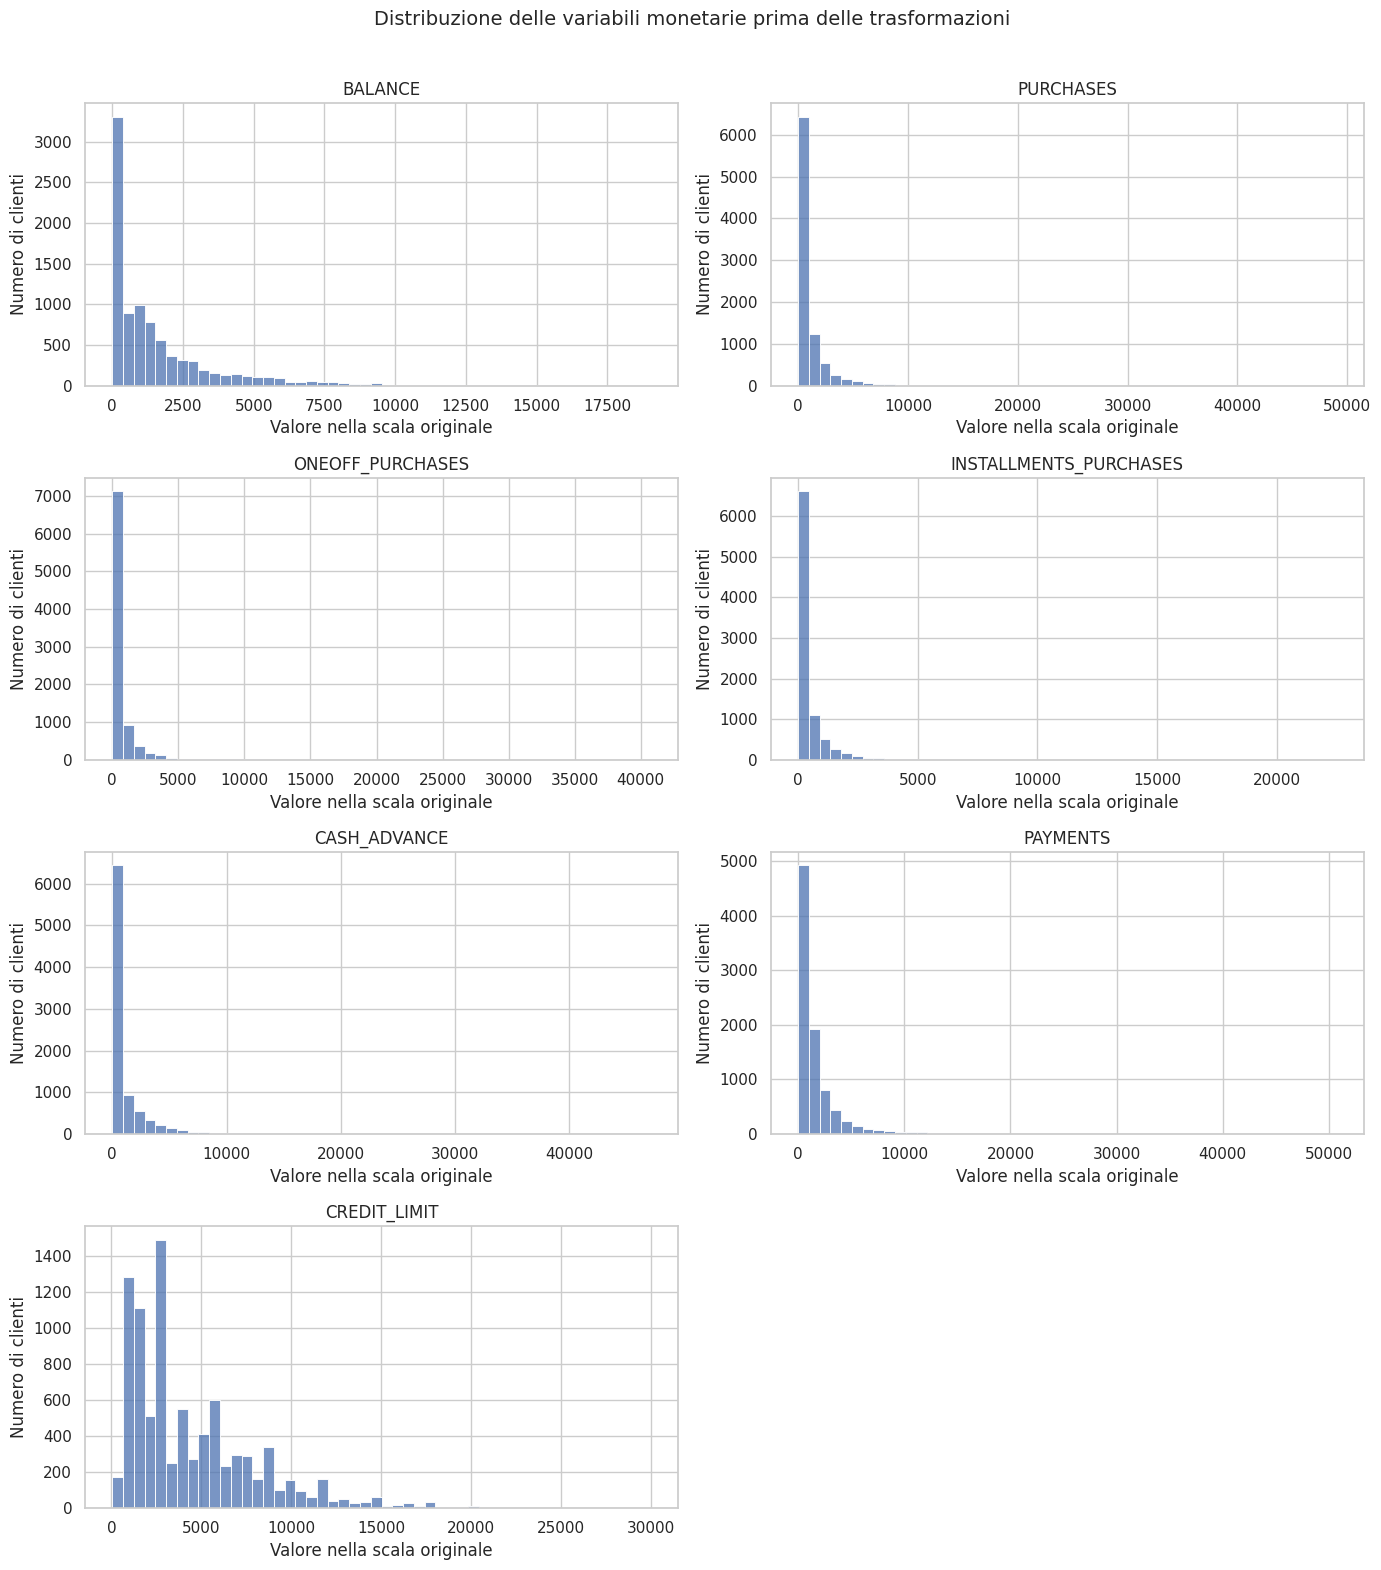

In [ ]:
# Variabili monetarie disponibili dopo il trattamento
monetary_features = [
    "BALANCE",
    "PURCHASES",
    "ONEOFF_PURCHASES",
    "INSTALLMENTS_PURCHASES",
    "CASH_ADVANCE",
    "PAYMENTS",
    "CREDIT_LIMIT"
]

monetary_data = df_clean[monetary_features]

# La quota di zeri è calcolata sui valori presenti
monetary_summary = pd.DataFrame({
    "valori_presenti": monetary_data.count(),
    "media": monetary_data.mean(),
    "mediana": monetary_data.median(),
    "percentile_95": monetary_data.quantile(0.95),
    "percentile_99": monetary_data.quantile(0.99),
    "massimo": monetary_data.max(),
    "percentuale_zeri": (
        monetary_data.eq(0).sum()
        .div(monetary_data.count())
        .mul(100)
    ),
    "asimmetria": monetary_data.skew()
})

print("DISTRIBUZIONE DELLE VARIABILI MONETARIE")
display(monetary_summary)

# Istogrammi nella scala originale
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.ravel()

for ax, feature in zip(axes, monetary_features):
    sns.histplot(
        x=df_clean[feature].dropna(),
        bins=50,
        kde=False,
        ax=ax
    )
    ax.set_title(feature)
    ax.set_xlabel("Valore nella scala originale")
    ax.set_ylabel("Numero di clienti")

# Rimozione del pannello non utilizzato
for ax in axes[len(monetary_features):]:
    ax.set_visible(False)

fig.suptitle(
    "Distribuzione delle variabili monetarie prima delle trasformazioni",
    fontsize=14
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### Interpretazione delle distribuzioni monetarie

Tutte le variabili monetarie esaminate presentano asimmetria positiva.

L’asimmetria è particolarmente marcata per ONEOFF_PURCHASES
(10,041), PURCHASES (8,144) e INSTALLMENTS_PURCHASES (7,317).
CREDIT_LIMIT presenta un’asimmetria più contenuta (1,523).

Gli istogrammi mostrano una concentrazione delle osservazioni
su importi relativamente bassi e code verso valori elevati.
Le medie risultano superiori alle rispettive mediane.

È inoltre rilevante la presenza di valori pari a zero:

- CASH_ADVANCE: 51,674%;
- ONEOFF_PURCHASES: 48,013%;
- INSTALLMENTS_PURCHASES: 43,825%;
- PURCHASES: 22,864%.

Questi valori vengono conservati, perché descrivono l’assenza
di utilizzo delle rispettive modalità nel periodo rappresentato
dai dati.

Le distribuzioni osservate motivano l’applicazione successiva
di log1p alle variabili monetarie. La trasformazione comprime
le differenze tra importi elevati e mantiene gli zeri.

Non si assume che la trasformazione renda le distribuzioni
normali: l’obiettivo è modificare il peso delle differenze
monetarie nelle distanze utilizzate da K-Means.

### Boxplot e valori estremi

I boxplot sintetizzano mediana, intervallo interquartile e
osservazioni esterne ai baffi.

L’intervallo interquartile è definito come:

IQR = Q3 − Q1

Le soglie utilizzate per individuare i valori esterni sono:

- soglia inferiore: Q1 − 1,5 × IQR;
- soglia superiore: Q3 + 1,5 × IQR.

Le osservazioni oltre queste soglie sono segnalazioni statistiche,
non necessariamente errori.

In distribuzioni asimmetriche possono rappresentare una quota
rilevante dei clienti. Non vengono quindi eliminate o limitate
automaticamente sulla base della sola regola dell’IQR.

Ogni variabile viene rappresentata con una propria scala verticale.

VALORI ESTERNI ALLE SOGLIE IQR


,Q1,Q3,IQR,soglia_inferiore,soglia_superiore,numero_sotto_soglia,numero_sopra_soglia,percentuale_fuori_soglie
BALANCE,128.432,2055.925,1927.492,-2762.806,4947.163,0,694,7.771
PURCHASES,39.000,1111.260,1072.260,-1569.390,2719.650,0,806,9.025
ONEOFF_PURCHASES,0.000,578.360,578.360,-867.540,1445.900,0,1011,11.320
INSTALLMENTS_PURCHASES,0.000,466.990,466.990,-700.485,1167.475,0,873,9.775
CASH_ADVANCE,0.000,1115.102,1115.102,-1672.652,2787.754,0,1029,11.522
PAYMENTS,383.278,1902.279,1519.001,-1895.223,4180.781,0,805,9.014
CREDIT_LIMIT,1600.000,6500.000,4900.000,-5750.000,13850.000,0,247,2.766


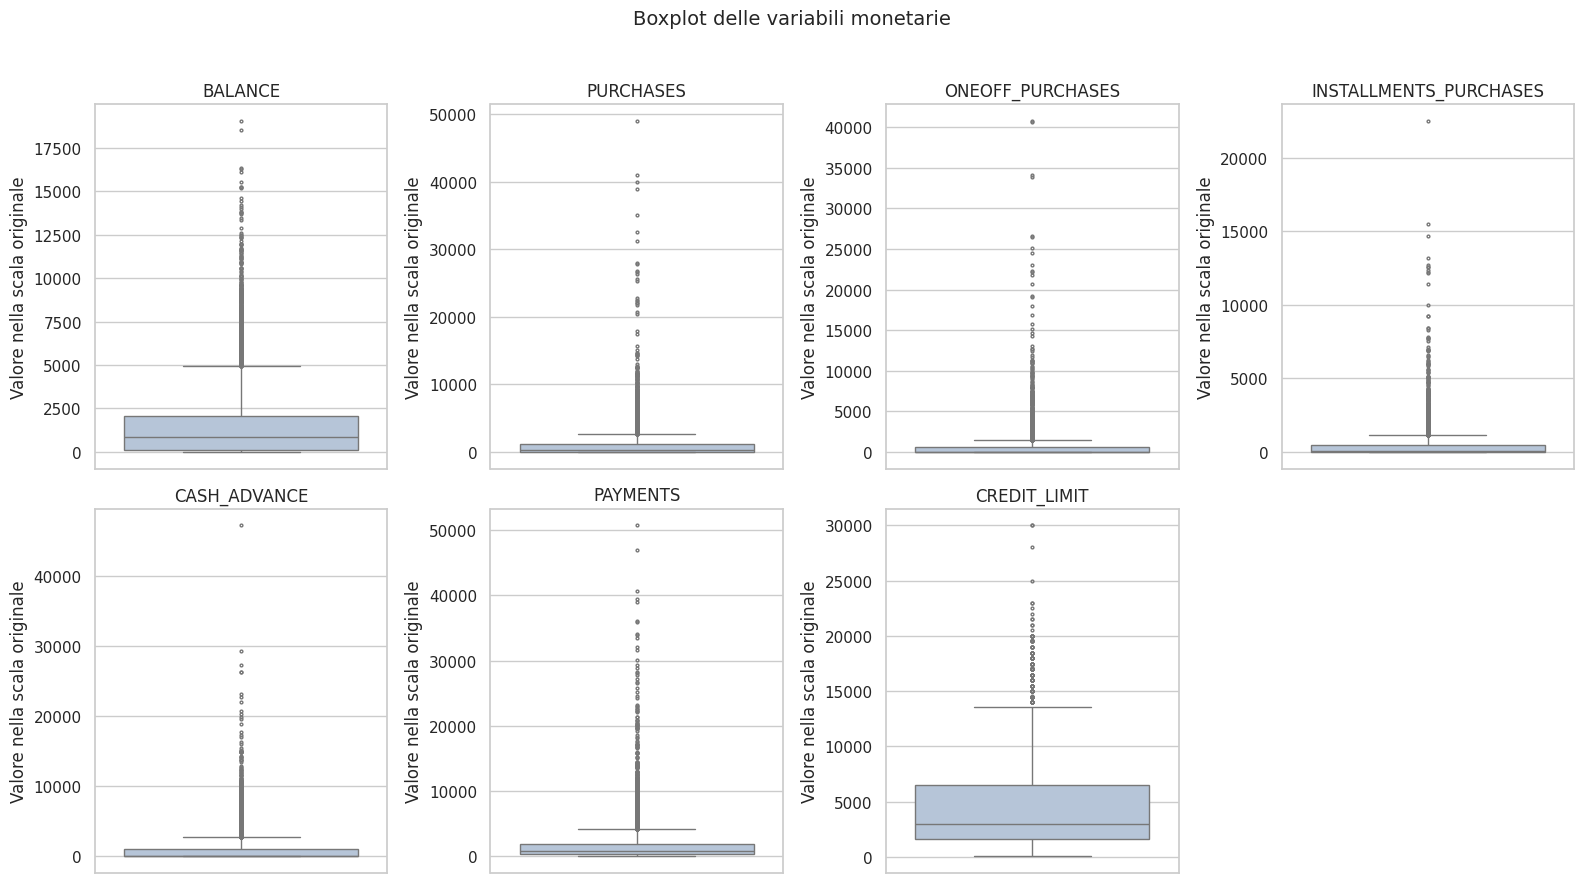

Analisi descrittiva completata: nessun valore modificato.


In [ ]:
# Soglie IQR per le variabili monetarie
q1 = monetary_data.quantile(0.25)
q3 = monetary_data.quantile(0.75)
iqr = q3 - q1

lower_bounds = q1 - 1.5 * iqr
upper_bounds = q3 + 1.5 * iqr

# Conteggio delle osservazioni esterne alle soglie
below_bounds = monetary_data.lt(lower_bounds, axis="columns").sum()
above_bounds = monetary_data.gt(upper_bounds, axis="columns").sum()

outlier_summary = pd.DataFrame({
    "Q1": q1,
    "Q3": q3,
    "IQR": iqr,
    "soglia_inferiore": lower_bounds,
    "soglia_superiore": upper_bounds,
    "numero_sotto_soglia": below_bounds,
    "numero_sopra_soglia": above_bounds,
    "percentuale_fuori_soglie": (
        (below_bounds + above_bounds)
        .div(monetary_data.count())
        .mul(100)
    )
})

print("VALORI ESTERNI ALLE SOGLIE IQR")
display(outlier_summary)

# Boxplot con scale indipendenti
fig, axes = plt.subplots(2, 4, figsize=(16, 9))
axes = axes.ravel()

for ax, feature in zip(axes, monetary_features):
    sns.boxplot(
        y=df_clean[feature].dropna(),
        ax=ax,
        color="lightsteelblue",
        whis=1.5,
        fliersize=2
    )
    ax.set_title(feature)
    ax.set_ylabel("Valore nella scala originale")

for ax in axes[len(monetary_features):]:
    ax.set_visible(False)

fig.suptitle(
    "Boxplot delle variabili monetarie",
    fontsize=14
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print("Analisi descrittiva completata: nessun valore modificato.")

### Interpretazione dei boxplot

Le osservazioni esterne alle soglie IQR si trovano esclusivamente
oltre la soglia superiore.

Le percentuali più elevate riguardano CASH_ADVANCE (11,522%) e
ONEOFF_PURCHASES (11,320%), mentre CREDIT_LIMIT presenta la quota
più contenuta (2,766%).

Questi risultati sono coerenti con le distribuzioni asimmetriche
osservate negli istogrammi.

Non vengono eliminate ulteriori osservazioni né applicati limiti
agli importi sulla base della sola regola dell’IQR. I valori
elevati potrebbero rappresentare comportamenti reali e rilevanti
per la segmentazione.

La successiva trasformazione logaritmica ridurrà il peso delle
differenze tra importi elevati nelle distanze utilizzate dal modello.

## 5. Preparazione delle variabili

La matrice delle feature viene costruita a partire da df_clean,
che recepisce il trattamento delle anomalie.

CUST_ID viene conservato separatamente ed escluso dal modello,
perché identifica il cliente senza descriverne il comportamento.

Le 16 variabili numeriche rimanenti costituiscono gli input
del clustering. Gli indici delle righe vengono mantenuti per
garantire l’allineamento tra feature, identificativi e successive
assegnazioni ai cluster.

In [ ]:
# Identificativi dei soli clienti mantenuti per il modello
customer_ids = df_clean["CUST_ID"].copy()

# Matrice delle feature, senza identificativo
df_model = df_clean.drop(columns=["CUST_ID"]).copy()

numeric_features = df_model.select_dtypes(
    include=np.number
).columns.tolist()

# Verifica che tutte le feature siano numeriche
assert len(numeric_features) == df_model.shape[1]
assert df_model.index.equals(customer_ids.index)
assert "MINIMUM_PAYMENTS" not in numeric_features

## 6. Gestione dei valori mancanti

Dopo il trattamento delle anomalie, i valori mancanti riguardano
CASH_ADVANCE_FREQUENCY e CREDIT_LIMIT.

Si applica l’imputazione tramite mediana, calcolata separatamente
per ogni variabile sui valori presenti dei clienti mantenuti.

La mediana è meno sensibile della media ai valori estremi.
L’imputazione rimane comunque una stima: non ricostruisce
necessariamente il valore effettivo del singolo cliente.

Viene conservato un riepilogo delle quantità imputate e dei
valori utilizzati. Il DataFrame df_imputed mantiene le unità
originali, prima della trasformazione logaritmica e della
standardizzazione.

L’imputer viene adattato all’intero dataset di modellazione,
poiché l’obiettivo attuale è una segmentazione descrittiva dei
clienti disponibili. Per assegnare nuovi clienti si dovrà
riutilizzare lo stesso imputer già adattato.

In [ ]:
# Valori mancanti prima dell'imputazione
missing_before = df_model.isna().sum()

# Imputazione tramite mediana
imputer = SimpleImputer(strategy="median")

X_imputed = imputer.fit_transform(df_model[numeric_features])

# Ricostruzione del DataFrame con indici e colonne originali
df_imputed = pd.DataFrame(
    X_imputed,
    columns=numeric_features,
    index=df_model.index
)

# Riepilogo delle sole variabili che richiedevano imputazione
imputation_summary = pd.DataFrame({
    "mancanti_prima": missing_before,
    "valore_di_imputazione": pd.Series(
        imputer.statistics_,
        index=numeric_features
    ),
    "mancanti_dopo": df_imputed.isna().sum()
})

print("RIEPILOGO DELL'IMPUTAZIONE")
display(
    imputation_summary.loc[
        imputation_summary["mancanti_prima"] > 0
    ]
)

# Verifiche su struttura e valori
assert df_imputed.shape == df_model.shape
assert df_imputed.index.equals(customer_ids.index)
assert np.isfinite(df_imputed.to_numpy()).all()

# Verifica che i valori originariamente presenti siano invariati
observed_mask = df_model.notna().to_numpy()

assert np.array_equal(
    df_model.to_numpy()[observed_mask],
    df_imputed.to_numpy()[observed_mask]
)

# Verifica del vincolo adottato per la frequenza degli anticipi
assert df_imputed["CASH_ADVANCE_FREQUENCY"].between(0, 1).all()

print("\nDimensioni della matrice imputata:", df_imputed.shape)
print(
    "Totale valori mancanti dopo l'imputazione:",
    int(df_imputed.isna().sum().sum())
)
print("Valori già presenti: mantenuti invariati.")
print("Allineamento con gli identificativi: verificato.")

RIEPILOGO DELL'IMPUTAZIONE


,mancanti_prima,valore_di_imputazione,mancanti_dopo
CASH_ADVANCE_FREQUENCY,8,0.000,0
CREDIT_LIMIT,1,3000.000,0



Dimensioni della matrice imputata: (8931, 16)
Totale valori mancanti dopo l'imputazione: 0
Valori già presenti: mantenuti invariati.
Allineamento con gli identificativi: verificato.


### Risultati dell’imputazione

L’imputazione tramite mediana ha sostituito:

- 8 valori mancanti di CASH_ADVANCE_FREQUENCY con 0;
- un valore mancante di CREDIT_LIMIT con 3.000.

La matrice risultante contiene 8.931 righe e 16 variabili numeriche,
senza valori mancanti o infiniti. I valori precedentemente presenti
e l’allineamento con gli identificativi sono rimasti invariati.

Lo zero imputato in CASH_ADVANCE_FREQUENCY è una stima e non
un’osservazione di mancato utilizzo. Per gli otto clienti interessati
può introdurre una discordanza con gli importi e i conteggi degli
anticipi, che sono stati conservati.

Questa limitazione viene mantenuta esplicita nell’interpretazione
del preprocessing.

## 7. Trasformazione logaritmica delle variabili monetarie

Le variabili monetarie presentano distribuzioni asimmetriche
positive e valori elevati che possono incidere sulle distanze
utilizzate da K-Means.

Si applica la trasformazione:

x_trasformato = ln(1 + x)

La funzione np.log1p calcola il logaritmo naturale di 1 + x,
consentendo di trasformare anche gli importi pari a zero.

La trasformazione viene applicata a:

- BALANCE;
- PURCHASES;
- ONEOFF_PURCHASES;
- INSTALLMENTS_PURCHASES;
- CASH_ADVANCE;
- PAYMENTS;
- CREDIT_LIMIT.

Frequenze, proporzioni, conteggi delle transazioni e TENURE
vengono mantenuti invariati in questo passaggio.

La trasformazione comprime le differenze tra importi elevati
e modifica quindi la geometria dei dati. Non garantisce
distribuzioni normali né un miglioramento automatico del clustering.

L’effetto viene esaminato confrontando l’asimmetria prima e dopo
la trasformazione e osservando gli istogrammi risultanti.

df_imputed viene conservato nella scala originale per la successiva
profilazione dei cluster. I valori trasformati sono salvati
separatamente in df_transformed.

CONFRONTO DELL'ASIMMETRIA
Una riduzione positiva indica minore asimmetria in valore assoluto.


,asimmetria_prima,asimmetria_dopo,riduzione_asimmetria_assoluta
BALANCE,2.392,-0.862,1.530
PURCHASES,8.144,-0.763,7.381
ONEOFF_PURCHASES,10.041,0.184,9.857
INSTALLMENTS_PURCHASES,7.317,-0.023,7.294
CASH_ADVANCE,5.164,0.261,4.903
PAYMENTS,5.903,-1.781,4.122
CREDIT_LIMIT,1.523,-0.102,1.421


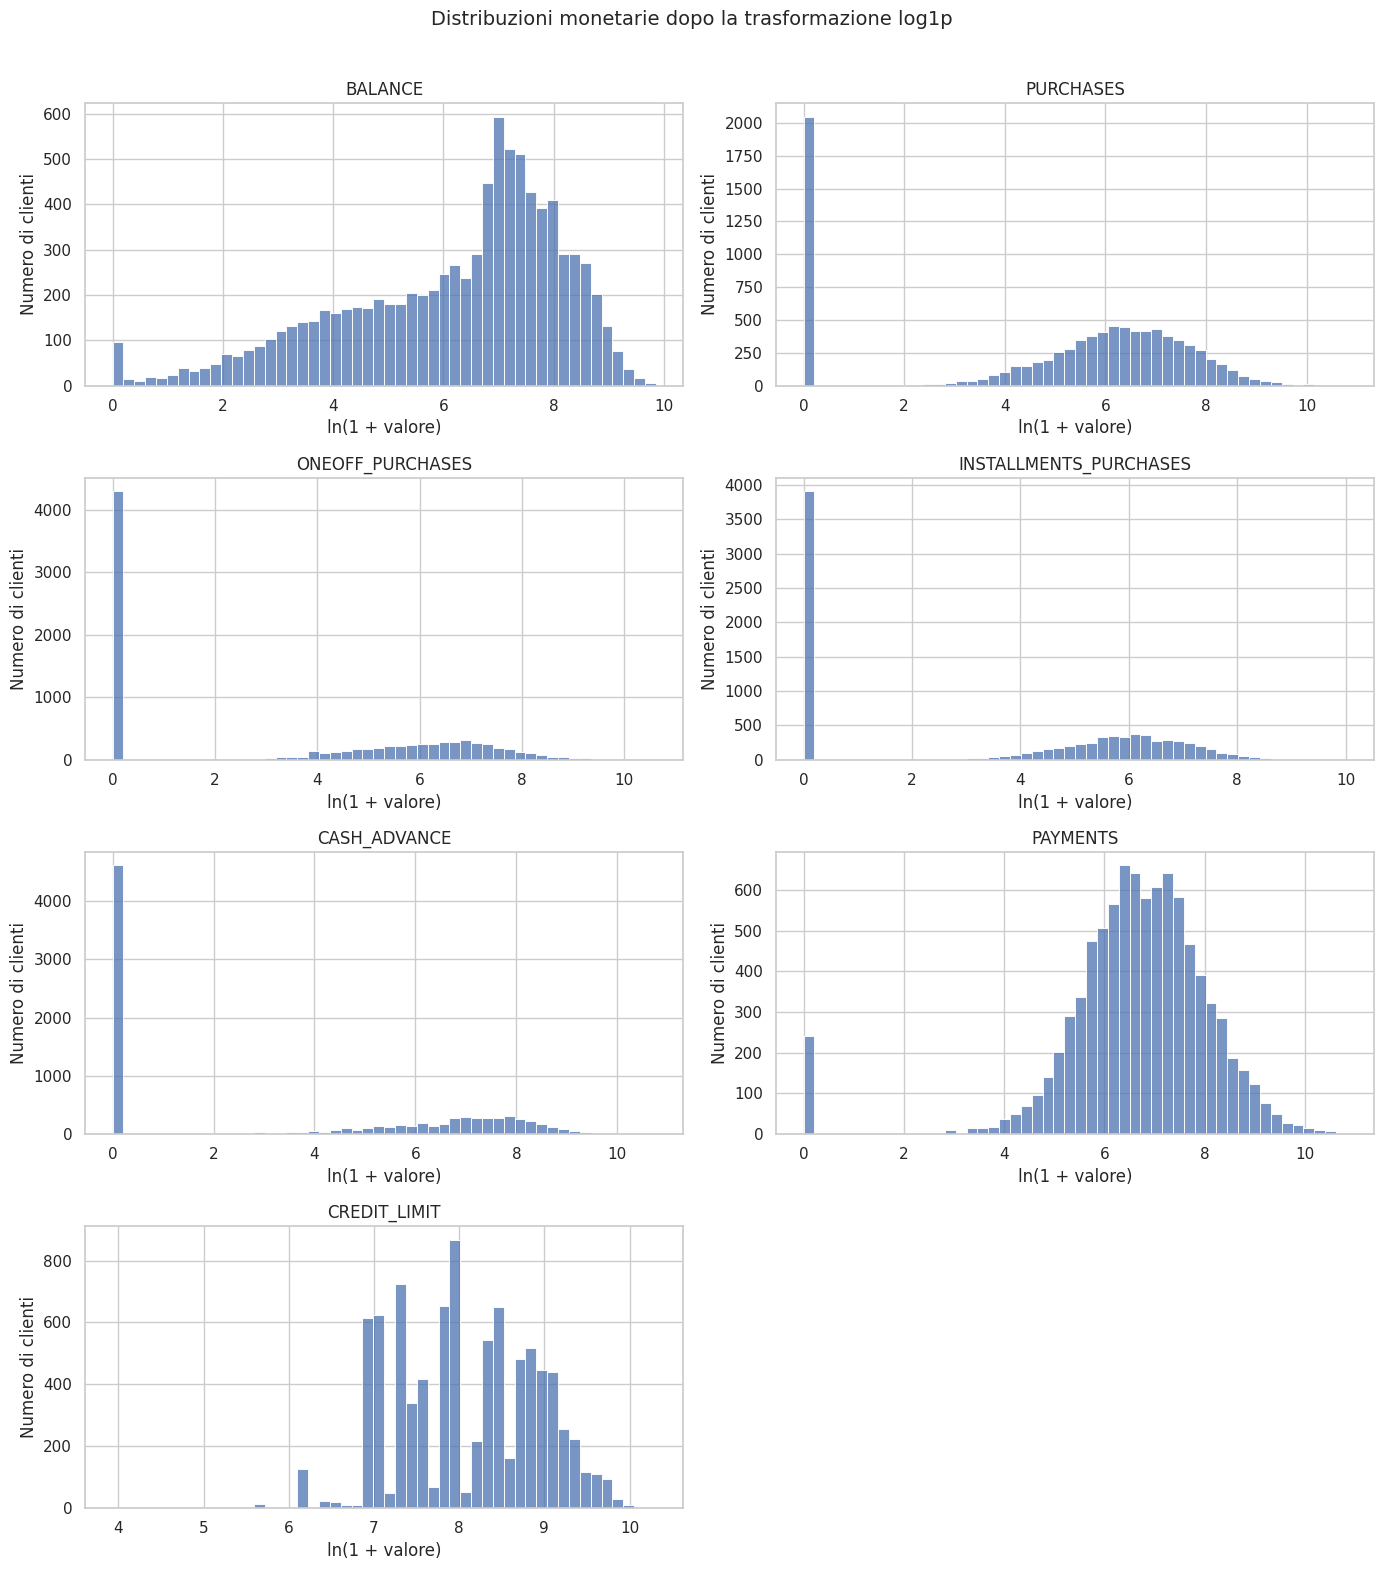

Trasformazione completata.
Variabili non monetarie mantenute invariate.


In [ ]:
# Variabili monetarie definite durante l'EDA
log_features = monetary_features.copy()

# Verifica del dominio previsto per gli importi
assert (df_imputed[log_features] >= 0).all().all()

# Copia separata: df_imputed resta nella scala originale
df_transformed = df_imputed.copy()

df_transformed[log_features] = np.log1p(
    df_imputed[log_features]
)

# Confronto dell'asimmetria
skewness_comparison = pd.DataFrame({
    "asimmetria_prima": df_imputed[log_features].skew(),
    "asimmetria_dopo": df_transformed[log_features].skew()
})

skewness_comparison["riduzione_asimmetria_assoluta"] = (
    skewness_comparison["asimmetria_prima"].abs()
    - skewness_comparison["asimmetria_dopo"].abs()
)

print("CONFRONTO DELL'ASIMMETRIA")
print("Una riduzione positiva indica minore asimmetria in valore assoluto.")
display(skewness_comparison)

# Verifiche essenziali
assert np.isfinite(df_transformed.to_numpy()).all()
assert df_transformed.index.equals(df_imputed.index)

non_log_features = [
    col for col in numeric_features if col not in log_features
]

assert df_transformed[non_log_features].equals(
    df_imputed[non_log_features]
)

# Istogrammi dopo log1p
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.ravel()

for ax, feature in zip(axes, log_features):
    sns.histplot(
        x=df_transformed[feature],
        bins=50,
        kde=False,
        ax=ax
    )
    ax.set_title(feature)
    ax.set_xlabel("ln(1 + valore)")
    ax.set_ylabel("Numero di clienti")

for ax in axes[len(log_features):]:
    ax.set_visible(False)

fig.suptitle(
    "Distribuzioni monetarie dopo la trasformazione log1p",
    fontsize=14
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

print("Trasformazione completata.")
print("Variabili non monetarie mantenute invariate.")

### Risultati della trasformazione logaritmica

La trasformazione log1p ha ridotto l’asimmetria in valore assoluto
per tutte le variabili monetarie analizzate.

Ad esempio:

- ONEOFF_PURCHASES passa da 10,041 a 0,184;
- INSTALLMENTS_PURCHASES passa da 7,317 a −0,023;
- CREDIT_LIMIT passa da 1,523 a −0,102.

Gli istogrammi evidenziano tuttavia che le concentrazioni di
osservazioni pari a zero rimangono presenti. Un indice di asimmetria
vicino a zero non dimostra quindi che la distribuzione sia normale.

BALANCE, PURCHASES e PAYMENTS presentano un’asimmetria negativa
dopo la trasformazione. In particolare, PAYMENTS mantiene una coda
verso i valori bassi, con asimmetria pari a −1,781.

Si mantiene la trasformazione adottata per comprimere le differenze
tra importi elevati, senza imporre la normalità delle distribuzioni.
La qualità della segmentazione sarà valutata nei passaggi successivi.

## 8. Standardizzazione delle variabili

K-Means utilizza distanze euclidee: le scale delle variabili
influenzano quindi la segmentazione.

Dopo la trasformazione logaritmica delle variabili monetarie,
tutte le 16 feature vengono standardizzate tramite StandardScaler:

z = (x − media) / deviazione standard

Per ogni variabile non costante, la standardizzazione produce
una media prossima a zero e una deviazione standard prossima a uno.

Questo passaggio rende confrontabili le scale, ma non elimina
i valori estremi, non rende normali le distribuzioni e non
rimuove le correlazioni tra le feature. Variabili correlate
possono quindi dare maggiore peso complessivo a uno stesso
aspetto del comportamento dei clienti.

Lo scaler viene adattato ai clienti del dataset di modellazione.
Per eventuali nuovi clienti dovranno essere riutilizzati lo stesso
preprocessing e lo stesso scaler già adattato.

La matrice standardizzata viene salvata in X_scaled. df_imputed
rimane disponibile nella scala originale per la profilazione.

In [ ]:
# Verifica preliminare: nessuna feature costante
constant_features = df_transformed.columns[
    df_transformed.nunique() <= 1
].tolist()

assert not constant_features, (
    f"Feature costanti da esaminare: {constant_features}"
)

# Standardizzazione di tutte le feature
scaler = StandardScaler()

X_scaled_array = scaler.fit_transform(df_transformed)

X_scaled = pd.DataFrame(
    X_scaled_array,
    columns=df_transformed.columns,
    index=df_transformed.index
)

# ddof=0 corrisponde alla convenzione utilizzata da StandardScaler
scaling_summary = pd.DataFrame({
    "media_dopo": X_scaled.mean(),
    "deviazione_standard_dopo": X_scaled.std(ddof=0),
    "minimo_dopo": X_scaled.min(),
    "massimo_dopo": X_scaled.max()
})

print("VERIFICA DELLA STANDARDIZZAZIONE")
display(scaling_summary)

# Controlli sulla matrice finale
assert np.isfinite(X_scaled.to_numpy()).all()
assert X_scaled.index.equals(customer_ids.index)
assert X_scaled.columns.tolist() == numeric_features
assert np.allclose(X_scaled.mean(), 0, atol=1e-10)
assert np.allclose(X_scaled.std(ddof=0), 1, atol=1e-10)

print("\nDimensioni della matrice per K-Means:", X_scaled.shape)
print("Valori mancanti:", int(X_scaled.isna().sum().sum()))
print("Controlli sulla standardizzazione superati.")

VERIFICA DELLA STANDARDIZZAZIONE


,media_dopo,deviazione_standard_dopo,minimo_dopo,massimo_dopo
BALANCE,-0.000,1.000,-3.061,1.834
BALANCE_FREQUENCY,0.000,1.000,-3.704,0.518
PURCHASES,-0.000,1.000,-1.679,2.023
ONEOFF_PURCHASES,0.000,1.000,-0.988,2.282
INSTALLMENTS_PURCHASES,-0.000,1.000,-1.086,2.164
CASH_ADVANCE,-0.000,1.000,-0.931,2.086
PURCHASES_FREQUENCY,0.000,1.000,-1.221,1.270
ONEOFF_PURCHASES_FREQUENCY,-0.000,1.000,-0.679,2.671
PURCHASES_INSTALLMENTS_FREQUENCY,0.000,1.000,-0.916,1.600
CASH_ADVANCE_FREQUENCY,0.000,1.000,-0.679,4.380



Dimensioni della matrice per K-Means: (8931, 16)
Valori mancanti: 0
Controlli sulla standardizzazione superati.


### Risultati della standardizzazione

La matrice X_scaled contiene 8.931 clienti e 16 feature,
senza valori mancanti o infiniti.

Tutte le variabili presentano media prossima a zero e
deviazione standard pari a uno.

I conteggi CASH_ADVANCE_TRX e PURCHASES_TRX mantengono valori
massimi standardizzati elevati, rispettivamente pari a circa
17,535 e 13,806. La standardizzazione rende confrontabili
le scale, ma non elimina i valori estremi.

Nella valutazione del clustering si esaminerà quindi anche
la numerosità dei segmenti, per verificare l’eventuale presenza
di gruppi molto piccoli caratterizzati da utilizzo estremo.

## 9. Valutazione del numero di cluster

Vengono confrontate soluzioni K-Means con un numero di cluster
compreso tra 2 e 8.

Per ogni soluzione vengono esaminati:

- inerzia, per valutare la compattezza dei gruppi;
- Silhouette Score, per valutare coesione e separazione;
- numerosità dei cluster, per descrivere la distribuzione
  della clientela tra i segmenti.

L’inerzia tende a diminuire all’aumentare del numero di cluster:
la sua riduzione deve quindi essere valutata rispetto all’aumento
della complessità della segmentazione.

Il Silhouette Score viene calcolato sull’intero dataset di
modellazione. Valori più elevati indicano una migliore
separazione secondo questa metrica.

Ogni modello utilizza 20 inizializzazioni e conserva la soluzione
con l’inerzia più bassa. Il parametro random_state è fissato
per favorire la riproducibilità.

I modelli e le assegnazioni vengono conservati per confrontare
successivamente i profili comportamentali dei clienti.

In [ ]:
# Intervallo di valori di K da confrontare
k_values = list(range(2, 9))
N_INIT = 20

# Conservazione dei modelli e delle assegnazioni
kmeans_models = {}
labels_by_k = {}
evaluation_rows = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=N_INIT
    )

    labels = model.fit_predict(X_scaled)

    kmeans_models[k] = model
    labels_by_k[k] = pd.Series(
        labels,
        index=X_scaled.index,
        name="cluster"
    )

    counts = labels_by_k[k].value_counts()

    # Calcolo sull'intero dataset: può richiedere qualche minuto
    score = silhouette_score(X_scaled, labels)

    evaluation_rows.append({
        "K": k,
        "inerzia": model.inertia_,
        "silhouette": score,
        "clienti_cluster_min": int(counts.min()),
        "clienti_cluster_max": int(counts.max()),
        "percentuale_cluster_min": 100 * counts.min() / len(X_scaled)
    })

evaluation_df = pd.DataFrame(evaluation_rows)

# Riduzione rispetto al K precedente nell'intervallo esplorato
evaluation_df["riduzione_inerzia_percentuale"] = (
    evaluation_df["inerzia"]
    .shift(1)
    .sub(evaluation_df["inerzia"])
    .div(evaluation_df["inerzia"].shift(1))
    .mul(100)
)

print("VALUTAZIONE DEI MODELLI")
display(evaluation_df.round(4))

print("\nCONFRONTO TRA LE DUE SOLUZIONI CANDIDATE")
display(
    evaluation_df.loc[
        evaluation_df["K"].isin([3, 4])
    ].round(4)
)

print("\nDISTRIBUZIONE DEI CLIENTI PER K = 3 E K = 4")

candidate_distributions = []

for k in [3, 4]:
    counts = labels_by_k[k].value_counts().sort_index()

    candidate_distributions.append(
        pd.DataFrame({
            "K": k,
            "cluster": counts.index,
            "numero_clienti": counts.to_numpy(),
            "percentuale_clienti": (
                100 * counts.to_numpy() / len(X_scaled)
            )
        })
    )

candidate_distribution = pd.concat(
    candidate_distributions,
    ignore_index=True
)

display(candidate_distribution.round(3))

VALUTAZIONE DEI MODELLI


,K,inerzia,silhouette,clienti_cluster_min,clienti_cluster_max,percentuale_cluster_min,riduzione_inerzia_percentuale
0,2,110355.118,0.227,4010,4921,44.900,NaN
1,3,94179.174,0.212,2524,3412,28.261,14.658
2,4,84992.940,0.211,1715,2806,19.203,9.754
3,5,77721.355,0.207,1022,2445,11.443,8.556
4,6,71170.620,0.218,731,2071,8.185,8.428
5,7,67149.785,0.221,528,1915,5.912,5.650
6,8,63683.508,0.211,491,1888,5.498,5.162



CONFRONTO TRA LE DUE SOLUZIONI CANDIDATE


,K,inerzia,silhouette,clienti_cluster_min,clienti_cluster_max,percentuale_cluster_min,riduzione_inerzia_percentuale
1,3,94179.174,0.212,2524,3412,28.261,14.658
2,4,84992.940,0.211,1715,2806,19.203,9.754



DISTRIBUZIONE DEI CLIENTI PER K = 3 E K = 4


,K,cluster,numero_clienti,percentuale_clienti
0,3,0,2524,28.261
1,3,1,2995,33.535
2,3,2,3412,38.204
3,4,0,2806,31.419
4,4,1,2184,24.454
5,4,2,2226,24.924
6,4,3,1715,19.203


## 10. Analisi del metodo Elbow

L’inerzia diminuisce da 110.355,118 con due cluster a 63.683,508
con otto cluster.

Il passaggio da due a tre cluster produce una riduzione
del 14,658%, mentre quello da tre a quattro una riduzione
del 9,754%. Le riduzioni successive sono più contenute.

L’andamento suggerisce benefici decrescenti all’aumentare
del numero di gruppi, senza evidenziare un gomito univoco.

Il metodo Elbow viene quindi utilizzato insieme alla silhouette
e all’interpretazione dei profili, senza determinare da solo
la scelta finale.

## 11. Analisi del Silhouette Score

Il valore più elevato nell’intervallo esaminato si osserva
con due cluster, con un punteggio di circa 0,227.

Le soluzioni con tre e quattro cluster presentano punteggi
vicini, rispettivamente circa 0,212 e 0,211. La separazione
risulta contenuta in entrambi i casi.

Le soluzioni con sei e sette cluster raggiungono silhouette
superiori a quelle con tre e quattro, ma comportano una
segmentazione più articolata.

Per approfondire il compromesso tra semplicità e capacità
descrittiva, vengono confrontati i profili delle soluzioni
con tre e quattro cluster.

Il confronto considera le medie delle variabili nella scala
originale e la redistribuzione dei clienti tra le due soluzioni.
Un gruppo aggiuntivo è utile se permette di distinguere
comportamenti rilevanti per le strategie di marketing,
non soltanto perché riduce l’inerzia.

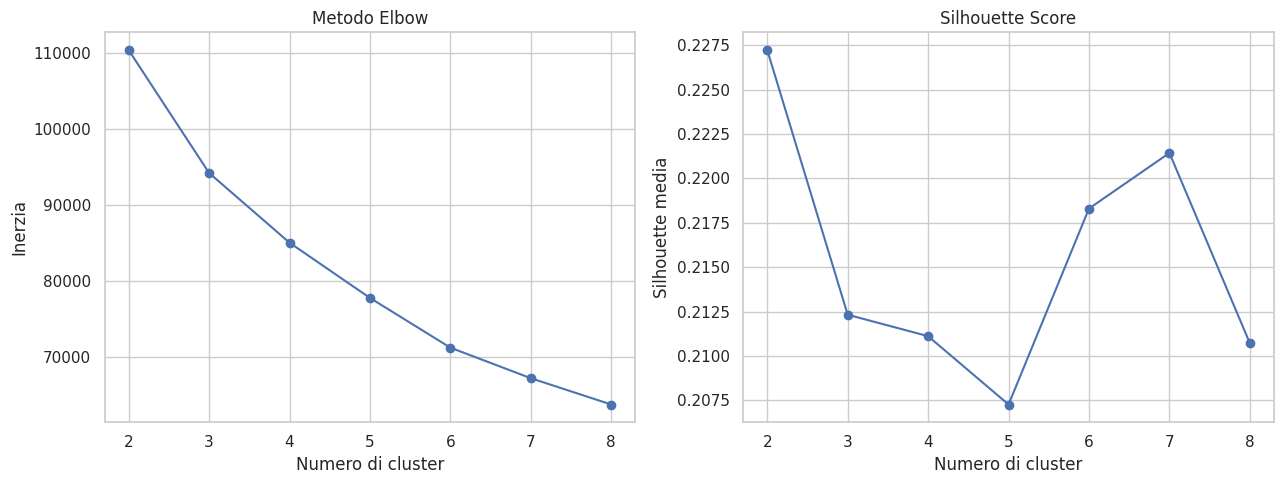


MEDIE DELLE VARIABILI ORIGINALI — K = 3


cluster,0,1,2
BALANCE,2140.395,2385.735,418.528
BALANCE_FREQUENCY,0.980,0.918,0.765
PURCHASES,2696.156,137.019,512.479
ONEOFF_PURCHASES,1723.230,109.885,181.445
INSTALLMENTS_PURCHASES,972.926,27.134,331.034
CASH_ADVANCE,787.650,2185.693,64.249
PURCHASES_FREQUENCY,0.876,0.090,0.556
ONEOFF_PURCHASES_FREQUENCY,0.546,0.052,0.082
PURCHASES_INSTALLMENTS_FREQUENCY,0.623,0.037,0.460
CASH_ADVANCE_FREQUENCY,0.103,0.296,0.015



MEDIE DELLE VARIABILI ORIGINALI — K = 4


cluster,0,1,2,3
BALANCE,2518.261,2184.570,685.129,357.558
BALANCE_FREQUENCY,0.943,0.979,0.925,0.578
PURCHASES,136.903,2901.188,696.124,404.741
ONEOFF_PURCHASES,110.123,1946.265,70.135,339.277
INSTALLMENTS_PURCHASES,26.780,954.923,625.989,65.463
CASH_ADVANCE,2281.246,791.309,184.819,123.962
PURCHASES_FREQUENCY,0.089,0.875,0.808,0.245
ONEOFF_PURCHASES_FREQUENCY,0.052,0.612,0.043,0.136
PURCHASES_INSTALLMENTS_FREQUENCY,0.036,0.590,0.755,0.105
CASH_ADVANCE_FREQUENCY,0.308,0.103,0.032,0.021



CONFRONTO DELLE ASSEGNAZIONI — NUMERO DI CLIENTI


Cluster con K=4,0,1,2,3
Cluster con K=3,,,,
0,17,2163,321,23
1,2780,0,30,185
2,9,21,1875,1507



CONFRONTO DELLE ASSEGNAZIONI — PERCENTUALI PER RIGA


Cluster con K=4,0,1,2,3
Cluster con K=3,,,,
0,0.670,85.700,12.720,0.910
1,92.820,0.000,1.000,6.180
2,0.260,0.620,54.950,44.170


In [ ]:
# Grafici delle metriche già calcolate
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    evaluation_df["K"],
    evaluation_df["inerzia"],
    marker="o"
)
axes[0].set_title("Metodo Elbow")
axes[0].set_xlabel("Numero di cluster")
axes[0].set_ylabel("Inerzia")

axes[1].plot(
    evaluation_df["K"],
    evaluation_df["silhouette"],
    marker="o"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Numero di cluster")
axes[1].set_ylabel("Silhouette media")

for ax in axes:
    ax.set_xticks(k_values)

plt.tight_layout()
plt.show()

# Profili nella scala originale, senza arrotondare i dati salvati
candidate_profiles = {}

for k in [3, 4]:
    profile_data = df_imputed.copy()
    profile_data["cluster"] = labels_by_k[k]

    profile = (
        profile_data
        .groupby("cluster")[numeric_features]
        .mean()
    )

    candidate_profiles[k] = profile

    print(f"\nMEDIE DELLE VARIABILI ORIGINALI — K = {k}")
    display(profile.T.round(3))

# Confronto delle assegnazioni:
# i numeri dei cluster sono etichette arbitrarie.
assignment_comparison = pd.crosstab(
    labels_by_k[3],
    labels_by_k[4],
    rownames=["Cluster con K=3"],
    colnames=["Cluster con K=4"]
)

print("\nCONFRONTO DELLE ASSEGNAZIONI — NUMERO DI CLIENTI")
display(assignment_comparison)

print("\nCONFRONTO DELLE ASSEGNAZIONI — PERCENTUALI PER RIGA")
display(
    assignment_comparison
    .div(assignment_comparison.sum(axis=1), axis=0)
    .mul(100)
    .round(2)
)

## 12. Scelta del numero di cluster

Si adotta una segmentazione a quattro cluster.

La scelta privilegia la possibilità di distinguere comportamenti
utili alla progettazione di campagne differenziate, mantenendo
un numero contenuto di segmenti.

Il confronto con la soluzione a tre cluster evidenzia soprattutto
la distinzione tra:

- clienti con acquisti frequenti prevalentemente rateali;
- clienti con acquisti meno frequenti prevalentemente
  in un’unica soluzione.

Nella soluzione a tre cluster questi comportamenti confluiscono
in larga parte nello stesso gruppo. La soluzione a quattro
consente quindi una descrizione più articolata della clientela.

Il Silhouette Score passa da circa 0,212 con tre cluster
a circa 0,211 con quattro: la maggiore articolazione non
corrisponde a un miglioramento della separazione secondo
questa metrica.

L’inerzia diminuisce del 9,754%, mentre tutti i segmenti
mantengono dimensioni consistenti: il più piccolo comprende
1.715 clienti, pari al 19,203% del dataset di modellazione.

La soluzione con due cluster presenta la silhouette più alta
nell’intervallo esaminato. La scelta di quattro cluster è
pertanto un compromesso interpretativo e operativo, non
un optimum dimostrato dalle sole metriche.

I quattro profili individuati vengono descritti provvisoriamente
come:

1. Utilizzo prevalente degli anticipi di contante.
2. Acquisti frequenti e di importo complessivo elevato.
3. Acquisti frequenti prevalentemente rateali.
4. Acquisti meno frequenti prevalentemente in un’unica soluzione.

Le etichette numeriche dei cluster sono arbitrarie e non
rappresentano un ordinamento dei clienti.

## 13. Applicazione del modello K-Means finale

Il modello con quattro cluster, già addestrato durante il confronto,
viene adottato come modello finale.

Il modello utilizza 20 inizializzazioni e random_state fissato.
Gli input sono le 16 feature preprocessate e standardizzate
contenute in X_scaled.

Le assegnazioni vengono associate ai clienti mantenendo
gli indici originali. L’etichetta del cluster viene aggiunta
a df_model e non alla matrice X_scaled utilizzata dal modello.

Vengono verificati:

- l’allineamento tra clienti e assegnazioni;
- l’assenza di etichette mancanti;
- la presenza di quattro cluster;
- la corrispondenza con le assegnazioni precedentemente analizzate.

Le metriche già calcolate sullo stesso modello vengono
riportate senza ripetere l’addestramento.

In [ ]:
# Numero di cluster scelto
K_SCELTO = 4

# Riutilizzo del modello e delle assegnazioni già analizzati
kmeans_final = kmeans_models[K_SCELTO]
final_labels = labels_by_k[K_SCELTO].copy()

# Ricostruzione delle feature originali per evitare colonne
# di segmentazione eventualmente presenti da esecuzioni precedenti
df_model = df_clean[numeric_features].copy()
df_model["cluster"] = final_labels

# Metriche del modello già valutato
selected_evaluation = (
    evaluation_df
    .set_index("K")
    .loc[K_SCELTO]
)

final_silhouette = float(selected_evaluation["silhouette"])
final_inertia = float(kmeans_final.inertia_)

# Controlli sulle assegnazioni
assert df_model.index.equals(customer_ids.index)
assert df_model["cluster"].notna().all()
assert df_model["cluster"].nunique() == K_SCELTO
assert len(df_model) == len(X_scaled)

assert np.array_equal(
    df_model["cluster"].to_numpy(),
    kmeans_final.labels_
)

assert np.isclose(
    final_inertia,
    selected_evaluation["inerzia"]
)

# Riepilogo
print("MODELLO K-MEANS FINALE")
print(f"Numero di cluster: {K_SCELTO}")
print(f"Clienti segmentati: {len(df_model)}")
print(f"Feature utilizzate: {X_scaled.shape[1]}")
print(f"Silhouette Score: {final_silhouette:.6f}")
print(f"Inerzia: {final_inertia:.3f}")

# Anteprima con identificativi correttamente allineati
assignment_preview = pd.DataFrame({
    "CUST_ID": customer_ids,
    "cluster": df_model["cluster"]
})

print("\nPRIME ASSEGNAZIONI")
display(assignment_preview.head(10))

print("\nControlli sul modello finale superati.")

MODELLO K-MEANS FINALE
Numero di cluster: 4
Clienti segmentati: 8931
Feature utilizzate: 16
Silhouette Score: 0.211117
Inerzia: 84992.940

PRIME ASSEGNAZIONI


,CUST_ID,cluster
0,C10001,3
1,C10002,0
2,C10003,1
3,C10004,3
4,C10005,3
5,C10006,2
6,C10007,1
7,C10008,2
8,C10009,2
9,C10010,3



Controlli sul modello finale superati.


## 14. Analisi della numerosità dei cluster

Vengono calcolati il numero e la percentuale di clienti appartenenti
a ciascun cluster.

Le percentuali sono riferite agli 8.931 clienti mantenuti nel
dataset di modellazione. I 19 clienti esclusi durante i controlli
di coerenza non partecipano alla segmentazione.

La numerosità permette di valutare la dimensione dei segmenti,
ma non costituisce da sola una misura della qualità del clustering.

In [ ]:
cluster_counts = (
    df_model["cluster"]
    .value_counts()
    .sort_index()
)

cluster_distribution = pd.DataFrame({
    "numero_clienti": cluster_counts,
    "percentuale_clienti": cluster_counts.div(len(df_model)).mul(100)
})

cluster_distribution.index.name = "cluster"

print("DISTRIBUZIONE DEI CLIENTI")
display(cluster_distribution.round(3))

DISTRIBUZIONE DEI CLIENTI


,numero_clienti,percentuale_clienti
cluster,,
0,2806,31.419
1,2184,24.454
2,2226,24.924
3,1715,19.203


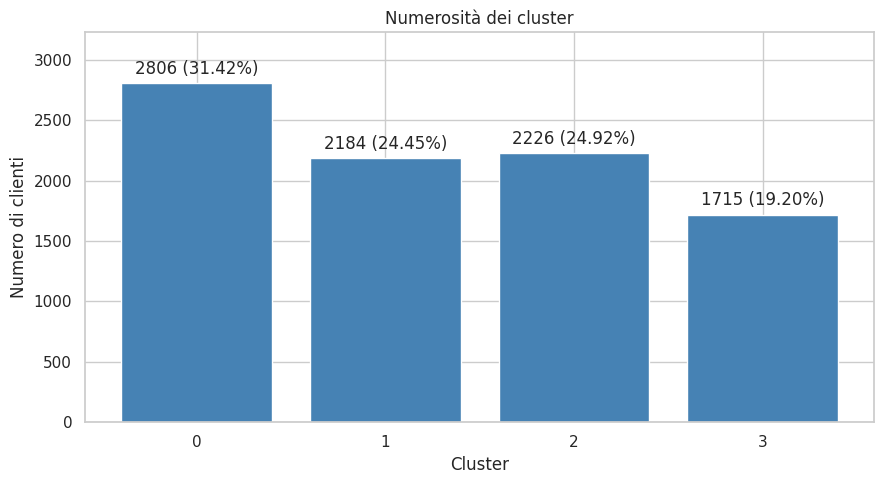

In [ ]:
# Grafico della numerosità
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    cluster_distribution.index.astype(str),
    cluster_distribution["numero_clienti"],
    color="steelblue"
)

bar_labels = [
    f"{int(row['numero_clienti'])} ({row['percentuale_clienti']:.2f}%)"
    for _, row in cluster_distribution.iterrows()
]

ax.bar_label(bars, labels=bar_labels, padding=4)
ax.set_title("Numerosità dei cluster")
ax.set_xlabel("Cluster")
ax.set_ylabel("Numero di clienti")
ax.set_ylim(0, cluster_counts.max() * 1.15)

plt.tight_layout()
plt.show()

## 15. Profilazione dei cluster

I cluster vengono descritti utilizzando le variabili di df_imputed,
nella scala originale, prima della trasformazione logaritmica e
della standardizzazione.

Per ogni segmento vengono calcolate:

- le medie di tutte le feature;
- le mediane delle variabili monetarie.

Le medie descrivono il livello medio del gruppo, ma possono essere
influenzate da pochi clienti con valori elevati. Le mediane
integrano questa informazione mostrando il valore centrale
della distribuzione.

La profilazione include i valori imputati. In particolare, gli
zeri imputati in CASH_ADVANCE_FREQUENCY non devono essere
interpretati come osservazioni certe di mancato utilizzo.

Le statistiche descrivono comportamenti aggregati: non implicano
che tutti i clienti di un cluster presentino le stesse caratteristiche.

In [ ]:
# Dataset per la profilazione nella scala originale
df_profile = df_imputed.copy()
df_profile["cluster"] = df_model["cluster"]

# Statistiche conservate senza arrotondamento
cluster_profile = (
    df_profile
    .groupby("cluster")[numeric_features]
    .mean()
)

cluster_medians = (
    df_profile
    .groupby("cluster")[numeric_features]
    .median()
)

# Riepilogo completo
cluster_profile_complete = cluster_profile.join(
    cluster_distribution
)

print("MEDIE DELLE FEATURE PER CLUSTER")
display(cluster_profile.T.round(3))

print("\nMEDIANE DELLE VARIABILI MONETARIE PER CLUSTER")
display(cluster_medians[monetary_features].T.round(3))

MEDIE DELLE FEATURE PER CLUSTER


cluster,0,1,2,3
BALANCE,2518.261,2184.570,685.129,357.558
BALANCE_FREQUENCY,0.943,0.979,0.925,0.578
PURCHASES,136.903,2901.188,696.124,404.741
ONEOFF_PURCHASES,110.123,1946.265,70.135,339.277
INSTALLMENTS_PURCHASES,26.780,954.923,625.989,65.463
CASH_ADVANCE,2281.246,791.309,184.819,123.962
PURCHASES_FREQUENCY,0.089,0.875,0.808,0.245
ONEOFF_PURCHASES_FREQUENCY,0.052,0.612,0.043,0.136
PURCHASES_INSTALLMENTS_FREQUENCY,0.036,0.590,0.755,0.105
CASH_ADVANCE_FREQUENCY,0.308,0.103,0.032,0.021



MEDIANE DELLE VARIABILI MONETARIE PER CLUSTER


cluster,0,1,2,3
BALANCE,1742.312,1310.412,188.626,58.314
PURCHASES,0.000,1970.095,483.050,195.000
ONEOFF_PURCHASES,0.000,1201.930,0.000,102.000
INSTALLMENTS_PURCHASES,0.000,532.600,421.580,0.000
CASH_ADVANCE,1433.522,0.000,0.000,0.000
PAYMENTS,928.507,1993.684,596.544,363.249
CREDIT_LIMIT,3000.000,6000.000,2000.000,2600.000


### Confronto tra medie e mediane

I quattro cluster comprendono quote della clientela comprese
tra il 19,203% e il 31,419%. Non sono presenti segmenti
di numerosità marginale.

Le mediane delle variabili monetarie sostengono la descrizione
dei profili:

- Cluster 0: acquisti mediani nulli e anticipi di contante
  mediani pari a 1.433,522;
- Cluster 1: acquisti mediani pari a 1.970,095, coerenti
  con un volume di acquisto relativamente elevato;
- Cluster 2: acquisti rateali mediani pari a 421,580
  e acquisti in unica soluzione mediani nulli;
- Cluster 3: acquisti mediani pari a 195, con mediana
  degli acquisti rateali nulla.

In diverse variabili le medie superano sensibilmente le mediane,
segnalando l’influenza dei valori elevati anche all’interno
dei segmenti.

Nel Cluster 1, ad esempio, CASH_ADVANCE presenta una media
di 791,309 ma una mediana nulla. Il ricorso agli anticipi
non deve quindi essere attribuito indistintamente a tutti
i clienti del gruppo.

## 16. Confronto tra i cluster e la media generale

Per ogni feature viene calcolata la differenza tra la media
del cluster e la media generale degli 8.931 clienti segmentati.

La media generale viene calcolata direttamente sui clienti,
così da tenere conto delle diverse dimensioni dei cluster.

Uno scostamento positivo indica un valore medio del segmento
superiore alla media generale; uno negativo indica un valore
inferiore.

Le differenze sono espresse nelle unità originali delle variabili.
La loro ampiezza non è quindi direttamente confrontabile
tra feature con scale differenti.

In [ ]:
# Statistiche generali nella scala originale
global_mean = df_imputed[numeric_features].mean()
global_std = df_imputed[numeric_features].std(ddof=0)

# Differenze nelle unità originali, senza arrotondamento
cluster_deviation = cluster_profile.sub(
    global_mean,
    axis="columns"
)

# Tabella di riferimento
profile_with_global = cluster_profile.T.copy()
profile_with_global.columns = [
    f"Cluster {cluster_id}"
    for cluster_id in profile_with_global.columns
]
profile_with_global.insert(0, "Media generale", global_mean)

## 17. Analisi degli scostamenti standardizzati

Per confrontare gli scostamenti di variabili con scale diverse,
si divide la differenza tra media del cluster e media generale
per la deviazione standard generale:

scostamento standardizzato =
(media del cluster − media generale) / deviazione standard generale

Un valore pari a +1 indica che la media del cluster supera
quella generale di una deviazione standard della variabile.
Un valore pari a −1 indica uno scostamento equivalente
nella direzione opposta.

La deviazione standard viene calcolata con ddof=0,
considerando l’insieme dei clienti segmentati.

Questi scostamenti sono indicatori descrittivi: non sono test
di significatività statistica né misure di importanza causale.

Sono calcolati sulle feature nella scala originale, dopo
l’imputazione. Non coincidono quindi con i centroidi di K-Means,
che sono definiti nello spazio trasformato e standardizzato.

In [ ]:
# Scostamenti standardizzati nella scala originale
assert (global_std > 0).all()

cluster_zscores = (
    cluster_deviation
    .div(global_std, axis="columns")
)

print("MEDIE DEI CLUSTER E MEDIA GENERALE")
display(profile_with_global.round(3))

print("\nSCOSTAMENTI DALLA MEDIA GENERALE — UNITÀ ORIGINALI")
display(cluster_deviation.T.round(3))

print("\nSCOSTAMENTI STANDARDIZZATI DALLA MEDIA GENERALE")
display(cluster_zscores.T.round(3))

MEDIE DEI CLUSTER E MEDIA GENERALE


,Media generale,Cluster 0,Cluster 1,Cluster 2,Cluster 3
BALANCE,1564.847,2518.261,2184.570,685.129,357.558
BALANCE_FREQUENCY,0.877,0.943,0.979,0.925,0.578
PURCHASES,1003.700,136.903,2901.188,696.124,404.741
ONEOFF_PURCHASES,593.173,110.123,1946.265,70.135,339.277
INSTALLMENTS_PURCHASES,410.527,26.780,954.923,625.989,65.463
CASH_ADVANCE,980.114,2281.246,791.309,184.819,123.962
PURCHASES_FREQUENCY,0.490,0.089,0.875,0.808,0.245
ONEOFF_PURCHASES_FREQUENCY,0.203,0.052,0.612,0.043,0.136
PURCHASES_INSTALLMENTS_FREQUENCY,0.364,0.036,0.590,0.755,0.105
CASH_ADVANCE_FREQUENCY,0.134,0.308,0.103,0.032,0.021



SCOSTAMENTI DALLA MEDIA GENERALE — UNITÀ ORIGINALI


cluster,0,1,2,3
BALANCE,953.414,619.723,-879.718,-1207.289
BALANCE_FREQUENCY,0.065,0.102,0.048,-0.299
PURCHASES,-866.797,1897.488,-307.576,-598.960
ONEOFF_PURCHASES,-483.050,1353.092,-523.038,-253.896
INSTALLMENTS_PURCHASES,-383.747,544.396,215.462,-345.064
CASH_ADVANCE,1301.132,-188.805,-795.295,-856.152
PURCHASES_FREQUENCY,-0.401,0.384,0.317,-0.245
ONEOFF_PURCHASES_FREQUENCY,-0.151,0.409,-0.160,-0.067
PURCHASES_INSTALLMENTS_FREQUENCY,-0.328,0.226,0.391,-0.259
CASH_ADVANCE_FREQUENCY,0.174,-0.031,-0.102,-0.113



SCOSTAMENTI STANDARDIZZATI DALLA MEDIA GENERALE


cluster,0,1,2,3
BALANCE,0.458,0.298,-0.423,-0.580
BALANCE_FREQUENCY,0.276,0.431,0.202,-1.262
PURCHASES,-0.405,0.888,-0.144,-0.280
ONEOFF_PURCHASES,-0.291,0.815,-0.315,-0.153
INSTALLMENTS_PURCHASES,-0.425,0.603,0.239,-0.382
CASH_ADVANCE,0.620,-0.090,-0.379,-0.408
PURCHASES_FREQUENCY,-0.999,0.958,0.790,-0.611
ONEOFF_PURCHASES_FREQUENCY,-0.505,1.370,-0.536,-0.223
PURCHASES_INSTALLMENTS_FREQUENCY,-0.825,0.569,0.984,-0.651
CASH_ADVANCE_FREQUENCY,0.880,-0.157,-0.516,-0.571


### Interpretazione degli scostamenti standardizzati

Il Cluster 0 presenta una frequenza degli anticipi superiore
alla media (+0,880) e una frequenza degli acquisti inferiore
alla media (−0,999). Il limite di credito medio è invece
vicino a quello generale (−0,010).

Il Cluster 1 si distingue per la frequenza degli acquisti
in unica soluzione (+1,370), il numero di transazioni di
acquisto (+1,022) e il volume complessivo degli acquisti
(+0,888).

Il Cluster 2 presenta una frequenza degli acquisti rateali
elevata (+0,984), accompagnata da acquisti complessivi
leggermente inferiori alla media (−0,144). Questo evidenzia
la distinzione tra frequenza di utilizzo e volume di spesa.

Il Cluster 3 presenta frequenze degli acquisti inferiori
alla media e una frequenza di aggiornamento del saldo
particolarmente bassa (−1,262). La prevalenza degli acquisti
in unica soluzione descrive la composizione degli acquisti
del segmento, non un volume superiore alla media generale.

TENURE presenta scostamenti medi contenuti in tutti i cluster.
Risulta quindi meno distintiva nel confronto effettuato,
senza che ciò dimostri l’assenza di un contributo al modello.

## 18. Visualizzazione degli scostamenti tramite heatmap

La heatmap rappresenta gli scostamenti standardizzati delle
medie dei cluster rispetto alla media generale.

Le righe corrispondono alle variabili e le colonne ai cluster:

- valori positivi indicano medie superiori a quella generale;
- valori negativi indicano medie inferiori;
- valori vicini a zero indicano medie prossime a quella generale.

La scala cromatica è simmetrica e centrata sullo zero, così
che scostamenti opposti della stessa ampiezza abbiano
un’intensità cromatica confrontabile.

Il grafico descrive differenze aggregate nella scala originale,
dopo l’imputazione. Non rappresenta i centroidi nello spazio
utilizzato da K-Means, la variabilità interna dei segmenti
o l’importanza causale delle feature.

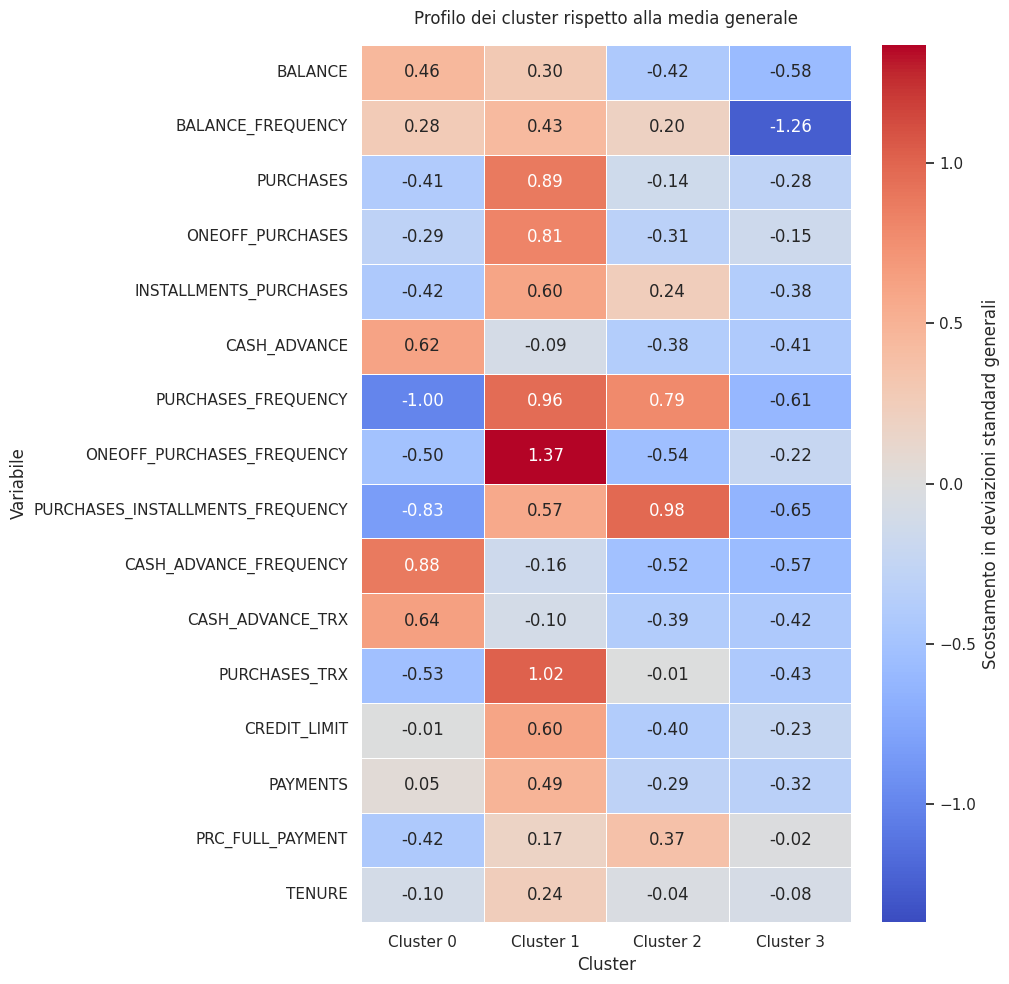

In [ ]:
# Variabili sulle righe per facilitare la lettura
heatmap_data = cluster_zscores.T.copy()

heatmap_data.columns = [
    f"Cluster {cluster_id}"
    for cluster_id in heatmap_data.columns
]

# Limiti simmetrici rispetto allo zero
color_limit = float(
    np.abs(heatmap_data.to_numpy()).max()
)

fig, ax = plt.subplots(figsize=(10, 10))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-color_limit,
    vmax=color_limit,
    linewidths=0.5,
    cbar_kws={
        "label": "Scostamento in deviazioni standard generali"
    },
    ax=ax
)

ax.set_title("Profilo dei cluster rispetto alla media generale", pad=15)
ax.set_xlabel("Cluster")
ax.set_ylabel("Variabile")
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

## 19. Visualizzazione dei cluster tramite PCA

La Principal Component Analysis (PCA) viene utilizzata per
rappresentare i clienti su un piano a due dimensioni.

La PCA viene applicata a X_scaled, la stessa matrice trasformata
e standardizzata utilizzata da K-Means. Le prime due componenti
sono combinazioni lineari delle feature che conservano la
massima varianza possibile per una proiezione lineare
bidimensionale.

La PCA viene impiegata esclusivamente per la visualizzazione:
il modello K-Means non viene riaddestrato e le assegnazioni
dei clienti non vengono modificate.

Viene riportata la percentuale di varianza spiegata da ciascuna
componente e complessivamente dalle prime due.

La proiezione perde parte dell’informazione presente nelle
16 dimensioni originali del modello. Eventuali sovrapposizioni
nel grafico non descrivono quindi completamente la separazione
nello spazio utilizzato dal clustering.

Nel grafico vengono rappresentati anche i centroidi del modello,
proiettati attraverso la stessa PCA.

VARIANZA SPIEGATA DALLA PCA


,componente,varianza_spiegata_percentuale,varianza_cumulata_percentuale
0,PC1,31.590,31.590
1,PC2,20.449,52.039


Varianza non rappresentata nel piano: 47.961%


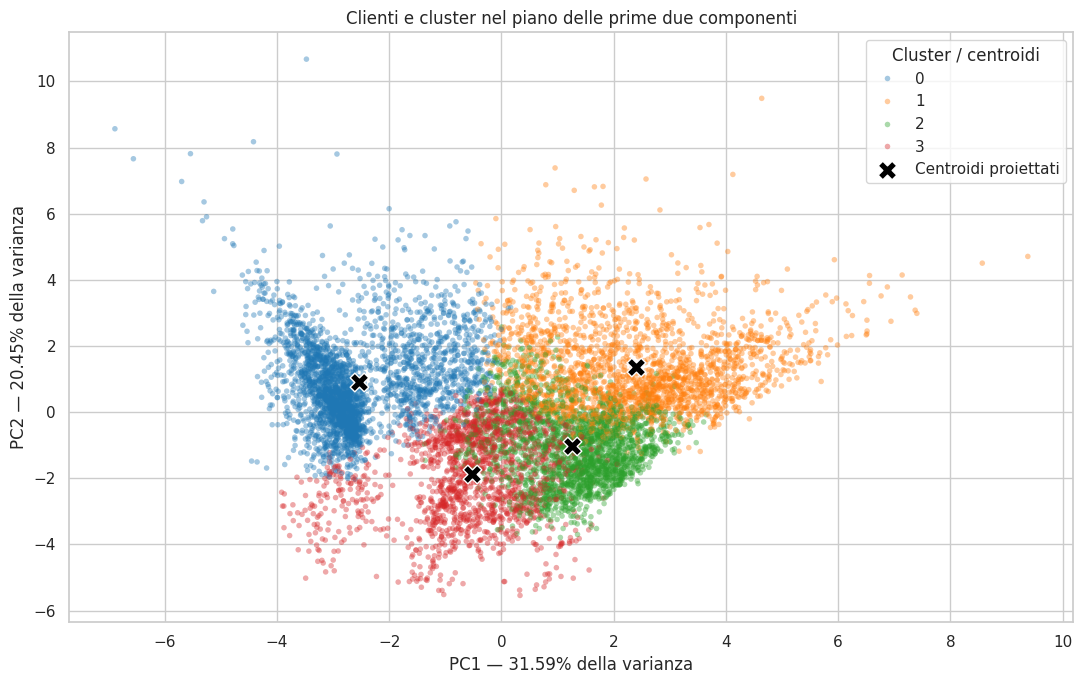

In [ ]:
# PCA deterministica tramite decomposizione completa
pca = PCA(n_components=2, svd_solver="full")

X_pca = pca.fit_transform(X_scaled)

# Coordinate dei clienti e assegnazioni già definite
df_pca = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"],
    index=X_scaled.index
)

df_pca["cluster"] = df_model["cluster"]

# Varianza spiegata
explained_variance = pca.explained_variance_ratio_

pca_summary = pd.DataFrame({
    "componente": ["PC1", "PC2"],
    "varianza_spiegata_percentuale": explained_variance * 100,
    "varianza_cumulata_percentuale": np.cumsum(
        explained_variance
    ) * 100
})

print("VARIANZA SPIEGATA DALLA PCA")
display(pca_summary.round(3))

print(
    "Varianza non rappresentata nel piano:",
    f"{(1 - explained_variance.sum()) * 100:.3f}%"
)

# Proiezione dei centroidi dallo spazio di K-Means
centers_scaled = pd.DataFrame(
    kmeans_final.cluster_centers_,
    columns=X_scaled.columns
)

centers_pca = pca.transform(centers_scaled)

# Colori distinti per etichette categoriche
cluster_order = sorted(df_model["cluster"].unique())
cluster_palette = dict(
    zip(cluster_order, sns.color_palette("tab10", n_colors=K_SCELTO))
)

# Ordine casuale di disegno per ridurre la sovrapposizione
# sistematica di un cluster sugli altri; tutti i clienti sono inclusi
plot_data = df_pca.sample(frac=1, random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(11, 7))

sns.scatterplot(
    data=plot_data,
    x="PC1",
    y="PC2",
    hue="cluster",
    hue_order=cluster_order,
    palette=cluster_palette,
    alpha=0.4,
    s=16,
    linewidth=0,
    ax=ax
)

ax.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    marker="X",
    s=180,
    c="black",
    edgecolors="white",
    linewidths=1,
    label="Centroidi proiettati",
    zorder=5
)

ax.set_title("Clienti e cluster nel piano delle prime due componenti")
ax.set_xlabel(f"PC1 — {explained_variance[0] * 100:.2f}% della varianza")
ax.set_ylabel(f"PC2 — {explained_variance[1] * 100:.2f}% della varianza")
ax.legend(title="Cluster / centroidi")

plt.tight_layout()
plt.show()

### Risultati della visualizzazione PCA

La prima componente principale spiega il 31,590% della varianza
e la seconda il 20,449%. Complessivamente, il piano rappresenta
il 52,039% della varianza dei dati preprocessati.

Il restante 47,961% non viene rappresentato nella visualizzazione.

I cluster occupano regioni parzialmente differenti del piano,
con sovrapposizioni nella zona centrale. La proiezione non
evidenzia quattro gruppi completamente separati.

Il grafico va interpretato insieme al Silhouette Score di 0,211117
e ai profili delle variabili. La segmentazione descrive tendenze
comportamentali aggregate, con differenze e sovrapposizioni
tra i clienti.

Non viene attribuito un significato economico specifico agli
assi PC1 e PC2 senza un’analisi dei coefficienti delle componenti.

## 20. Interpretazione dei segmenti individuati

L’interpretazione integra numerosità, medie, mediane e
scostamenti standardizzati. Le descrizioni sintetizzano
i comportamenti dei gruppi e non si applicano necessariamente
a ogni singolo cliente.

### Cluster 0 — Utilizzo prevalente degli anticipi di contante

Comprende 2.806 clienti, pari al 31,419% della clientela segmentata.

Gli anticipi di contante presentano una media di 2.281,246
e una mediana di 1.433,522. Gli acquisti hanno invece
una media di 136,903 e una mediana nulla.

La frequenza media degli acquisti è 0,089, mentre quella
degli anticipi è 0,308, superiore alla media generale.

Il profilo descrive un utilizzo della carta prevalentemente
orientato agli anticipi. Queste caratteristiche non dimostrano
da sole difficoltà economiche o rischio di insolvenza.

### Cluster 1 — Acquisti frequenti e di importo complessivo elevato

Comprende 2.184 clienti, pari al 24,454%.

Gli acquisti medi sono pari a 2.901,188, con mediana di 1.970,095.
La frequenza media degli acquisti è 0,875 e il numero medio
di transazioni di acquisto è 40,117.

Sono presenti sia acquisti in unica soluzione sia rateali.
Il limite di credito medio, pari a 6.676,906, è superiore
alla media generale.

Il gruppo si distingue per l’intensità degli acquisti.
L’elevato volume di spesa non permette però di determinarne
automaticamente la redditività per l’azienda.

### Cluster 2 — Acquisti frequenti prevalentemente rateali

Comprende 2.226 clienti, pari al 24,924%.

Gli acquisti rateali medi sono pari a 625,989, su acquisti
complessivi medi di 696,124. La frequenza media degli
acquisti rateali è 0,755.

La mediana degli acquisti rateali è 421,580, mentre quella
degli acquisti in unica soluzione è nulla.

Il segmento presenta quindi acquisti frequenti, prevalentemente
rateali, con importi complessivi inferiori alla media generale.

PRC_FULL_PAYMENT ha una media di 0,263, la più alta tra
i segmenti. Questo valore è la media dell’indicatore,
non la percentuale di clienti che pagano sempre integralmente.

### Cluster 3 — Acquisti meno frequenti prevalentemente in unica soluzione

Comprende 1.715 clienti, pari al 19,203%.

Gli acquisti complessivi medi sono pari a 404,741, di cui
339,277 in unica soluzione. La frequenza media degli
acquisti è 0,245, inferiore alla media generale.

La mediana degli acquisti complessivi è 195, mentre
quella degli acquisti rateali è nulla.

La prevalenza degli acquisti in unica soluzione riguarda
la composizione degli acquisti del segmento, non un volume
superiore a quello della clientela complessiva.

Il minore utilizzo osservato non consente, da solo,
di identificare clienti in abbandono o disinteressati
alle offerte aziendali.

In [ ]:
# Nomi descrittivi coerenti con i profili analizzati
cluster_names = {
    0: "Utilizzo prevalente degli anticipi di contante",
    1: "Acquisti frequenti e di importo complessivo elevato",
    2: "Acquisti frequenti prevalentemente rateali",
    3: "Acquisti meno frequenti prevalentemente in unica soluzione"
}

# Associazione dei nomi alle assegnazioni
df_model["cluster_name"] = df_model["cluster"].map(cluster_names)
df_pca["cluster_name"] = df_pca["cluster"].map(cluster_names)

# Profilo completo ricostruito per consentire la riesecuzione
cluster_profile_complete = cluster_profile.join(
    cluster_distribution
)

cluster_profile_complete.insert(
    0,
    "cluster_name",
    cluster_profile_complete.index.map(cluster_names)
)

# Tabella sintetica dei segmenti
segment_summary = cluster_distribution.copy()

segment_summary.insert(
    0,
    "cluster_name",
    segment_summary.index.map(cluster_names)
)

# Verifica della copertura della mappatura
assert df_model["cluster_name"].notna().all()
assert segment_summary["numero_clienti"].sum() == len(df_model)

print("RIEPILOGO DEI SEGMENTI")
display(segment_summary.round(3))

print("\nCLIENTI CON CLUSTER E NOME DEL SEGMENTO")
display(
    customer_ids.to_frame().join(
        df_model[["cluster", "cluster_name"]]
    ).head(10).T
)

RIEPILOGO DEI SEGMENTI


,cluster_name,numero_clienti,percentuale_clienti
cluster,,,
0,Utilizzo prevalente degli anticipi di contante,2806,31.419
1,Acquisti frequenti e di importo complessivo el...,2184,24.454
2,Acquisti frequenti prevalentemente rateali,2226,24.924
3,Acquisti meno frequenti prevalentemente in uni...,1715,19.203



CLIENTI CON CLUSTER E NOME DEL SEGMENTO


,0,1,2,3,4,5,6,7,8,9
CUST_ID,C10001,C10002,C10003,C10004,C10005,C10006,C10007,C10008,C10009,C10010
cluster,3,0,1,3,3,2,1,2,2,3
cluster_name,Acquisti meno frequenti prevalentemente in uni...,Utilizzo prevalente degli anticipi di contante,Acquisti frequenti e di importo complessivo el...,Acquisti meno frequenti prevalentemente in uni...,Acquisti meno frequenti prevalentemente in uni...,Acquisti frequenti prevalentemente rateali,Acquisti frequenti e di importo complessivo el...,Acquisti frequenti prevalentemente rateali,Acquisti frequenti prevalentemente rateali,Acquisti meno frequenti prevalentemente in uni...


## 21. Individuazione delle caratteristiche principali dei cluster

Per ciascun cluster vengono selezionate le cinque variabili
con il maggiore scostamento standardizzato in valore assoluto
rispetto alla media generale.

L’uso degli scostamenti standardizzati consente di confrontare
variabili espresse su scale differenti. Il valore assoluto
serve a ordinare le caratteristiche, mentre il segno viene
conservato per distinguere valori superiori e inferiori
alla media generale.

Per ogni caratteristica vengono riportati:

- media del cluster;
- media generale;
- scostamento standardizzato;
- direzione dello scostamento.

La selezione sintetizza i profili già analizzati. Non rappresenta
una misura dell’importanza delle feature nell’algoritmo né
una verifica indipendente della qualità dei cluster.

Le variabili correlate possono descrivere aspetti simili
dello stesso comportamento e comparire insieme nella selezione.

In [ ]:
TOP_N = 5
distinctive_rows = []

for cluster_id in cluster_profile.index:
    # Ordinamento per ampiezza dello scostamento
    selected_features = (
        cluster_zscores.loc[cluster_id]
        .abs()
        .sort_values(ascending=False)
        .head(TOP_N)
        .index
    )

    for rank, feature in enumerate(selected_features, start=1):
        z_value = float(cluster_zscores.loc[cluster_id, feature])

        distinctive_rows.append({
            "cluster": cluster_id,
            "posizione": rank,
            "variabile": feature,
            "media_cluster": cluster_profile.loc[cluster_id, feature],
            "media_generale": global_mean[feature],
            "scostamento_standardizzato": z_value,
            "direzione": (
                "Sopra la media" if z_value > 0
                else "Sotto la media" if z_value < 0
                else "Uguale alla media"
            )
        })

# Risultati conservati senza arrotondamento
cluster_distinctive_features = pd.DataFrame(distinctive_rows)

# Una tabella compatta per ciascun segmento
for cluster_id in cluster_profile.index:
    print(f"\nCLUSTER {cluster_id} — {cluster_names[cluster_id]}")

    display(
        cluster_distinctive_features.loc[
            cluster_distinctive_features["cluster"] == cluster_id
        ]
        .drop(columns="cluster")
        .set_index("posizione")
        .round(3)
    )


CLUSTER 0 — Utilizzo prevalente degli anticipi di contante


,variabile,media_cluster,media_generale,scostamento_standardizzato,direzione
posizione,,,,,
1,PURCHASES_FREQUENCY,0.089,0.490,-0.999,Sotto la media
2,CASH_ADVANCE_FREQUENCY,0.308,0.134,0.880,Sopra la media
3,PURCHASES_INSTALLMENTS_FREQUENCY,0.036,0.364,-0.825,Sotto la media
4,CASH_ADVANCE_TRX,7.617,3.252,0.639,Sopra la media
5,CASH_ADVANCE,2281.246,980.114,0.620,Sopra la media



CLUSTER 1 — Acquisti frequenti e di importo complessivo elevato


,variabile,media_cluster,media_generale,scostamento_standardizzato,direzione
posizione,,,,,
1,ONEOFF_PURCHASES_FREQUENCY,0.612,0.203,1.370,Sopra la media
2,PURCHASES_TRX,40.117,14.708,1.022,Sopra la media
3,PURCHASES_FREQUENCY,0.875,0.490,0.958,Sopra la media
4,PURCHASES,2901.188,1003.700,0.888,Sopra la media
5,ONEOFF_PURCHASES,1946.265,593.173,0.815,Sopra la media



CLUSTER 2 — Acquisti frequenti prevalentemente rateali


,variabile,media_cluster,media_generale,scostamento_standardizzato,direzione
posizione,,,,,
1,PURCHASES_INSTALLMENTS_FREQUENCY,0.755,0.364,0.984,Sopra la media
2,PURCHASES_FREQUENCY,0.808,0.490,0.790,Sopra la media
3,ONEOFF_PURCHASES_FREQUENCY,0.043,0.203,-0.536,Sotto la media
4,CASH_ADVANCE_FREQUENCY,0.032,0.134,-0.516,Sotto la media
5,BALANCE,685.129,1564.847,-0.423,Sotto la media



CLUSTER 3 — Acquisti meno frequenti prevalentemente in unica soluzione


,variabile,media_cluster,media_generale,scostamento_standardizzato,direzione
posizione,,,,,
1,BALANCE_FREQUENCY,0.578,0.877,-1.262,Sotto la media
2,PURCHASES_INSTALLMENTS_FREQUENCY,0.105,0.364,-0.651,Sotto la media
3,PURCHASES_FREQUENCY,0.245,0.490,-0.611,Sotto la media
4,BALANCE,357.558,1564.847,-0.580,Sotto la media
5,CASH_ADVANCE_FREQUENCY,0.021,0.134,-0.571,Sotto la media


## 22. Strategie di marketing differenziate

Le strategie proposte derivano dai comportamenti osservati nei
cluster e rappresentano ipotesi operative da verificare.

Il dataset non contiene risposte a campagne precedenti, preferenze
dichiarate, costi di marketing o margini individuali. Non è quindi
possibile stimare direttamente conversioni, redditività o ritorno
sull’investimento delle proposte.

### Cluster 0 — Utilizzo prevalente degli anticipi di contante

**Evidenza:** frequenza degli anticipi superiore alla media,
accompagnata da una bassa frequenza degli acquisti.

**Obiettivo:** favorire la conoscenza delle funzionalità della
carta e sperimentarne un maggiore utilizzo per acquisti ordinari.

**Proposta:** una comunicazione chiara sui costi degli anticipi
e sulle modalità di utilizzo della carta, accompagnata da un
piccolo incentivo con tetto massimo per acquisti presso esercenti.

**Indicatore principale:** quota di clienti che effettuano
almeno un acquisto nel periodo della campagna.

**Indicatori secondari:** numero di transazioni di acquisto
per cliente e utilizzo dell’incentivo.

### Cluster 1 — Acquisti frequenti e di importo complessivo elevato

**Evidenza:** frequenza, numero di transazioni e importi
degli acquisti superiori alla media.

**Obiettivo:** sostenere la continuità di utilizzo della carta.

**Proposta:** un programma fedeltà o un cashback con tetto
massimo, eventualmente associato a una rete di esercenti.
Il dataset non consente di selezionare categorie merceologiche
preferite dai singoli clienti.

**Indicatore principale:** numero di transazioni di acquisto
per cliente nel periodo di osservazione.

**Indicatori secondari:** quota di clienti attivi e margine
incrementale al netto del costo dei premi, se disponibile.

Poiché questi clienti acquistano già frequentemente, occorre
verificare che l’incentivo generi un beneficio aggiuntivo
rispetto al comportamento che si sarebbe verificato comunque.

### Cluster 2 — Acquisti frequenti prevalentemente rateali

**Evidenza:** frequenza degli acquisti rateali superiore
alla media e basso utilizzo degli acquisti in unica soluzione.

**Obiettivo:** migliorare l’esperienza di gestione degli
acquisti rateali e sostenere la continuità di utilizzo.

**Proposta:** comunicazioni sulle funzionalità di riepilogo
delle rate e delle scadenze, con informazioni trasparenti
sui costi. Si può sperimentare un’offerta sui costi del
servizio, senza assumere la necessità di aumentare gli
importi finanziati.

**Indicatore principale:** quota di clienti che utilizzano
la funzionalità o l’offerta proposta.

**Indicatori secondari:** continuità degli acquisti nel
periodo successivo e soddisfazione rilevata tramite questionario.

La maggiore adozione della funzionalità non dimostra, da sola,
un aumento della redditività.

### Cluster 3 — Acquisti meno frequenti prevalentemente in unica soluzione

**Evidenza:** frequenza degli acquisti inferiore alla media,
con prevalenza degli acquisti in unica soluzione all’interno
del segmento.

**Obiettivo:** sperimentare un aumento della frequenza di utilizzo.

**Proposta:** una campagna semplice con un incentivo contenuto
per un acquisto successivo alla comunicazione. Un breve
questionario può aiutare a comprendere i motivi del minore
utilizzo, che non sono presenti nel dataset.

**Indicatore principale:** quota di clienti che effettuano
almeno un acquisto durante la campagna.

**Indicatori secondari:** numero di transazioni per cliente
e persistenza dell’utilizzo dopo la fine dell’incentivo.

Il segmento non viene definito “in abbandono”, perché il
dataset non permette di verificare una diminuzione individuale
dell’utilizzo nel tempo.

### Validazione delle campagne

Per ogni segmento si propone un test con assegnazione casuale
dei clienti a:

- gruppo destinatario della campagna;
- gruppo di controllo, che mantiene le comunicazioni ordinarie.

Prima dell’avvio devono essere definiti l’indicatore principale,
la durata, il budget e la numerosità necessaria a rilevare
un effetto di interesse.

Il confronto deve includere tutti i clienti assegnati ai gruppi,
non soltanto quelli che aprono la comunicazione o utilizzano
l’offerta.

Per indicatori espressi come quote, la differenza tra gruppo
campagna e controllo viene riportata in punti percentuali,
accompagnata da una misura dell’incertezza.

Quando disponibili, ricavi, costi degli incentivi e costi
operativi permetteranno di valutare anche il risultato economico.
Un aumento delle transazioni non equivale automaticamente
a un aumento del profitto.

La segmentazione non viene utilizzata, da sola, per decidere
aumenti del limite di credito o valutare l’affidabilità finanziaria
individuale.

In [ ]:
# Proposte da validare: non sono risultati di campagne già eseguite
marketing_actions = pd.DataFrame([
    {
        "cluster": 0,
        "obiettivo": "Sperimentare l'utilizzo per acquisti ordinari",
        "proposta": "Informazioni sui costi e incentivo acquisti con tetto",
        "indicatore_principale": "Quota di clienti con almeno un acquisto"
    },
    {
        "cluster": 1,
        "obiettivo": "Sostenere la continuità di utilizzo",
        "proposta": "Programma fedeltà o cashback con tetto",
        "indicatore_principale": "Transazioni di acquisto per cliente"
    },
    {
        "cluster": 2,
        "obiettivo": "Migliorare la gestione degli acquisti rateali",
        "proposta": "Riepilogo rate e scadenze; offerta sui costi del servizio",
        "indicatore_principale": "Quota di clienti che aderiscono alla proposta"
    },
    {
        "cluster": 3,
        "obiettivo": "Sperimentare un aumento della frequenza di acquisto",
        "proposta": "Incentivo contenuto per un acquisto successivo",
        "indicatore_principale": "Quota di clienti con almeno un acquisto"
    }
]).set_index("cluster")

marketing_summary = segment_summary.join(
    marketing_actions,
    validate="one_to_one"
)

print("STRATEGIE PROPOSTE PER SEGMENTO")

# Visualizzazione verticale per evitare il troncamento dei testi
for cluster_id, row in marketing_summary.iterrows():
    print(f"\nCLUSTER {cluster_id} — {row['cluster_name']}")

    with pd.option_context("display.max_colwidth", None):
        display(
            row.drop(labels="cluster_name")
            .to_frame(name="Descrizione")
        )

STRATEGIE PROPOSTE PER SEGMENTO

CLUSTER 0 — Utilizzo prevalente degli anticipi di contante


,Descrizione
numero_clienti,2806
percentuale_clienti,31.419
obiettivo,Sperimentare l'utilizzo per acquisti ordinari
proposta,Informazioni sui costi e incentivo acquisti con tetto
indicatore_principale,Quota di clienti con almeno un acquisto



CLUSTER 1 — Acquisti frequenti e di importo complessivo elevato


,Descrizione
numero_clienti,2184
percentuale_clienti,24.454
obiettivo,Sostenere la continuità di utilizzo
proposta,Programma fedeltà o cashback con tetto
indicatore_principale,Transazioni di acquisto per cliente



CLUSTER 2 — Acquisti frequenti prevalentemente rateali


,Descrizione
numero_clienti,2226
percentuale_clienti,24.924
obiettivo,Migliorare la gestione degli acquisti rateali
proposta,Riepilogo rate e scadenze; offerta sui costi del servizio
indicatore_principale,Quota di clienti che aderiscono alla proposta



CLUSTER 3 — Acquisti meno frequenti prevalentemente in unica soluzione


,Descrizione
numero_clienti,1715
percentuale_clienti,19.203
obiettivo,Sperimentare un aumento della frequenza di acquisto
proposta,Incentivo contenuto per un acquisto successivo
indicatore_principale,Quota di clienti con almeno un acquisto


## 23. Esportazione dei risultati

I risultati vengono esportati in file CSV distinti:

- clienti_segmentati_kmeans.csv: clienti segmentati, feature
  dopo l’imputazione nella scala originale, cluster e nome
  del segmento;
- clienti_esclusi.csv: osservazioni escluse, con i valori
  originali e il motivo dell’esclusione;
- registro_qualita_dati.csv: segnalazioni di qualità e
  indicatori di imputazione per tutti i clienti originali;
- profili_cluster.csv: medie delle feature per segmento,
  numerosità e percentuali;
- strategie_marketing.csv: proposte operative e indicatori
  di valutazione.

Nel dataset segmentato, CASH_ADVANCE_FREQUENCY e CREDIT_LIMIT
contengono i valori imputati nei casi documentati. Due colonne
booleane identificano le osservazioni interessate.

MINIMUM_PAYMENTS non viene inclusa nel dataset segmentato,
perché esclusa dalle feature del modello. Rimane disponibile
nei dati originali.

I 19 clienti esclusi non ricevono un cluster. Il registro di
qualità conserva i loro identificativi e permette di distinguere
le esclusioni dalle osservazioni effettivamente segmentate.

I file vengono salvati in una cartella dedicata e raccolti
in un archivio ZIP scaricabile. L’archivio contiene risultati
e tabelle di supporto, non gli oggetti addestrati del modello.

In [ ]:
from pathlib import Path
import shutil

# Cartella di output nel runtime Colab
output_dir = Path("output_segmentazione")
output_dir.mkdir(parents=True, exist_ok=True)

# Indicatori delle celle effettivamente imputate
imputed_flags = df_clean[
    ["CASH_ADVANCE_FREQUENCY", "CREDIT_LIMIT"]
].isna()

imputed_flags = imputed_flags.rename(columns={
    "CASH_ADVANCE_FREQUENCY": "cash_advance_frequency_imputata",
    "CREDIT_LIMIT": "credit_limit_imputato"
})

# Dataset segmentato: feature imputate nella scala originale
df_segmented = customer_ids.to_frame().join(df_imputed)

df_segmented = df_segmented.join(
    df_model[["cluster", "cluster_name"]]
).join(imputed_flags)

# Registro di qualità esteso a tutti i clienti originali
quality_export = quality_audit.copy()

for col in imputed_flags.columns:
    quality_export[col] = imputed_flags[col].reindex(
        quality_export.index,
        fill_value=False
    )

quality_export["stato_segmentazione"] = np.where(
    quality_export["escluso_dal_modello"],
    "Escluso: incoerenza negli acquisti",
    "Segmentato"
)

# Etichetta intera nullable: assente per i clienti esclusi
quality_export["cluster"] = (
    df_model["cluster"]
    .reindex(quality_export.index)
    .astype("Int64")
)

# Tabelle da esportare
export_tables = {
    "clienti_segmentati_kmeans.csv": df_segmented,
    "clienti_esclusi.csv": df_excluded,
    "registro_qualita_dati.csv": quality_export,
    "profili_cluster.csv": cluster_profile_complete.reset_index(),
    "strategie_marketing.csv": marketing_summary.reset_index()
}

# Esportazione e verifica dei file riletti
export_report = []

for filename, table in export_tables.items():
    file_path = output_dir / filename

    table.to_csv(
        file_path,
        index=False,
        encoding="utf-8-sig"
    )

    reloaded = pd.read_csv(file_path)

    assert reloaded.shape == table.shape
    assert reloaded.columns.tolist() == table.columns.tolist()

    export_report.append({
        "file": filename,
        "righe": len(reloaded),
        "colonne": reloaded.shape[1],
        "dimensione_KB": file_path.stat().st_size / 1024
    })

# Archivio contenente esattamente i file previsti
# I file vengono aggiunti esplicitamente per evitare altri contenuti.
from zipfile import ZipFile, ZIP_DEFLATED

archive_path = Path("risultati_segmentazione_kmeans.zip")

with ZipFile(archive_path, "w", compression=ZIP_DEFLATED) as archive:
    for filename in export_tables:
        archive.write(
            output_dir / filename,
            arcname=filename
        )

print("FILE ESPORTATI E RILETTI")
display(pd.DataFrame(export_report).round(2))

print("\nVALORI IMPUTATI NEL DATASET SEGMENTATO")
display(
    df_segmented[list(imputed_flags.columns)]
    .sum()
    .to_frame(name="numero_clienti")
)

print(f"\nArchivio creato: {archive_path.name}")
print("Esportazione completata.")

FILE ESPORTATI E RILETTI


,file,righe,colonne,dimensione_KB
0,clienti_segmentati_kmeans.csv,8931,21,1499.130
1,clienti_esclusi.csv,19,19,3.360
2,registro_qualita_dati.csv,8950,10,540.170
3,profili_cluster.csv,4,20,1.790
4,strategie_marketing.csv,4,7,0.920



VALORI IMPUTATI NEL DATASET SEGMENTATO


,numero_clienti
cash_advance_frequency_imputata,8
credit_limit_imputato,1



Archivio creato: risultati_segmentazione_kmeans.zip
Esportazione completata.


## 24. Controlli finali e conclusioni

### Verifica della coerenza dei risultati

Vengono effettuati i seguenti controlli:

- ogni identificativo originale compare tra i clienti segmentati
  oppure tra quelli esclusi, senza sovrapposizioni;
- tutti i clienti segmentati hanno un cluster e un nome coerente;
- le assegnazioni esportate coincidono con quelle del modello;
- le feature esportate coincidono con i valori dopo l’imputazione;
- i clienti esclusi non hanno un cluster nel registro di qualità;
- i profili esportati corrispondono alle medie dei clienti segmentati;
- l’archivio ZIP contiene i cinque file previsti ed è integro.

Queste verifiche accertano la coerenza tecnica degli output.
Non dimostrano la validità delle ipotesi di preprocessing
né l’efficacia commerciale della segmentazione.

In [ ]:
# Rilettura dei principali risultati esportati
segmented_check = pd.read_csv(
    output_dir / "clienti_segmentati_kmeans.csv"
)
excluded_check = pd.read_csv(
    output_dir / "clienti_esclusi.csv"
)
audit_check = pd.read_csv(
    output_dir / "registro_qualita_dati.csv"
)
profiles_check = pd.read_csv(
    output_dir / "profili_cluster.csv"
)

original_ids = set(df_original["CUST_ID"])
segmented_ids = set(segmented_check["CUST_ID"])
excluded_ids = set(excluded_check["CUST_ID"])

# Completezza e unicità degli identificativi
assert segmented_check["CUST_ID"].is_unique
assert excluded_check["CUST_ID"].is_unique
assert audit_check["CUST_ID"].is_unique

assert segmented_ids.isdisjoint(excluded_ids)
assert segmented_ids | excluded_ids == original_ids
assert set(audit_check["CUST_ID"]) == original_ids
assert len(segmented_check) + len(excluded_check) == len(df_original)

# Assegnazioni e nomi
assert segmented_check[["cluster", "cluster_name"]].notna().all().all()
assert set(segmented_check["cluster"]) == set(range(K_SCELTO))

assert segmented_check["cluster_name"].equals(
    segmented_check["cluster"].map(cluster_names)
)

# Allineamento per identificativo, indipendente dall'ordine delle righe
expected = df_segmented.set_index("CUST_ID")
actual = (
    segmented_check
    .set_index("CUST_ID")
    .loc[expected.index]
)

assert np.array_equal(
    actual["cluster"].to_numpy(),
    expected["cluster"].to_numpy()
)

# Piccole tolleranze per la conversione numerica CSV
assert np.allclose(
    actual[numeric_features].to_numpy(),
    expected[numeric_features].to_numpy(),
    rtol=1e-10,
    atol=1e-10
)

flag_columns = [
    "cash_advance_frequency_imputata",
    "credit_limit_imputato"
]

assert np.array_equal(
    actual[flag_columns].to_numpy(),
    expected[flag_columns].to_numpy()
)

# Registro: cluster presenti soltanto per i clienti segmentati
audit_by_id = audit_check.set_index("CUST_ID")

assert audit_by_id.loc[
    list(excluded_ids), "cluster"
].isna().all()

assert np.array_equal(
    audit_by_id.loc[expected.index, "cluster"].to_numpy(),
    expected["cluster"].to_numpy()
)

# Coerenza dei profili con il dataset segmentato esportato
recomputed_profiles = (
    segmented_check
    .groupby("cluster")[numeric_features]
    .mean()
)

saved_profiles = (
    profiles_check
    .set_index("cluster")
    .loc[recomputed_profiles.index]
)

assert np.allclose(
    saved_profiles[numeric_features].to_numpy(),
    recomputed_profiles.to_numpy(),
    rtol=1e-10,
    atol=1e-10
)

assert np.array_equal(
    saved_profiles["numero_clienti"].to_numpy(),
    segmented_check.groupby("cluster").size().to_numpy()
)

# Integrità e contenuto dell'archivio
with ZipFile(archive_path, "r") as archive:
    assert archive.testzip() is None
    assert set(archive.namelist()) == set(export_tables)

    for filename in export_tables:
        assert archive.read(filename) == (
            output_dir / filename
        ).read_bytes()

print("CONTROLLI FINALI SUPERATI")
print(f"Clienti originali: {len(df_original)}")
print(f"Clienti segmentati: {len(segmented_check)}")
print(f"Clienti esclusi e conservati separatamente: {len(excluded_check)}")
print(f"Numero di cluster: {K_SCELTO}")
print(f"Silhouette Score: {final_silhouette:.6f}")
print(f"Inerzia: {final_inertia:.3f}")
print("Assegnazioni, feature, profili e archivio verificati.")

CONTROLLI FINALI SUPERATI
Clienti originali: 8950
Clienti segmentati: 8931
Clienti esclusi e conservati separatamente: 19
Numero di cluster: 4
Silhouette Score: 0.211117
Inerzia: 84992.940
Assegnazioni, feature, profili e archivio verificati.


### Conclusioni

Il progetto ha segmentato 8.931 clienti attraverso K-Means,
utilizzando 16 variabili relative al comportamento di utilizzo
della carta di credito.

Il preprocessing ha previsto:

- controlli di coerenza prima dell’imputazione;
- separazione di 19 osservazioni con incoerenze negli acquisti;
- esclusione di MINIMUM_PAYMENTS dalle feature;
- trattamento di otto frequenze di anticipo superiori a 1
  secondo l’ipotesi operativa documentata;
- imputazione tramite mediana;
- trasformazione logaritmica delle variabili monetarie;
- standardizzazione delle feature.

La soluzione a quattro cluster distingue:

| Cluster | Profilo | Clienti | Percentuale |
| --- | --- | ---: | ---: |
| 0 | Utilizzo prevalente degli anticipi di contante | 2.806 | 31,419% |
| 1 | Acquisti frequenti e di importo complessivo elevato | 2.184 | 24,454% |
| 2 | Acquisti frequenti prevalentemente rateali | 2.226 | 24,924% |
| 3 | Acquisti meno frequenti prevalentemente in unica soluzione | 1.715 | 19,203% |

La scelta di quattro cluster privilegia la distinzione tra
comportamenti utili alla formulazione di campagne differenziate.
Non corrisponde al massimo Silhouette Score nell’intervallo
esaminato, ottenuto con due cluster.

Il modello finale presenta un Silhouette Score di 0,211117:
la separazione è contenuta e i segmenti non devono essere
interpretati come categorie nettamente distinte.

La rappresentazione PCA conserva il 52,039% della varianza
e fornisce una sintesi parziale della struttura dei dati.

### Limiti e sviluppi futuri

Le scelte di trattamento dipendono dalle definizioni disponibili.
In particolare, l’esclusione di MINIMUM_PAYMENTS comporta una
perdita informativa, mentre l’interpretazione di
CASH_ADVANCE_FREQUENCY come frequenza limitata a [0, 1]
richiede conferma dalla fonte.

L’imputazione a zero delle otto frequenze invalidate non
equivale a un’osservazione di mancato utilizzo degli anticipi.

Le variabili correlate possono attribuire un peso complessivo
maggiore ad alcuni comportamenti. Inoltre, i conteggi delle
transazioni mantengono valori estremi dopo la standardizzazione.

Non è stata misurata la stabilità della segmentazione rispetto
a campionamenti, semi casuali o scelte alternative di preprocessing.
Le inizializzazioni multiple riducono la dipendenza da una singola
inizializzazione, ma non sostituiscono questa verifica.

Ulteriori sviluppi comprendono la verifica delle definizioni con
il fornitore dei dati, l’analisi di sensibilità del preprocessing
e la valutazione della stabilità dei cluster nel tempo.

Le campagne proposte sono ipotesi da sperimentare con gruppi
di controllo. Il dataset non permette di dimostrare incrementi
di conversione, fidelizzazione o profitto.

La segmentazione descrive comportamenti aggregati e non
costituisce una valutazione individuale del rischio finanziario.